# Experiment 4 — density against topology

## What happens here

Experiment 1 established that a witness neuron appears when the feature is **needed by the task**:
one and the same circle gave a witness in 49 models of 50 where it separates the classes, and in 0 of 50
where it does not. Experiment 2 showed that this is not an artefact of the architecture.

Both left one competing explanation open. In both datasets the task-relevant circle was
**also the place where the points lie most densely**, and the research plan keeps on its list of
confounds the hypothesis "level sets stick to concentrations of points" (the density effect, Section 1 of the
paper). As long as these two circumstances
coincide, the conclusion "the witness appears because of relevance" holds no more firmly than "the witness
appears because of density".

## Main goal

**To separate two explanations of why a witness neuron appears — "the task forces a closed boundary in this
place" and "in this place the points lie more densely" — and to measure which of them actually controls
the quality of the witness.**

## Tasks

| | question | how we answer it |
|---|---|---|
| **D** | relative to what should the score be computed at all — what is the target, what is the floor, where is the threshold? | four targets and their nulls, in each configuration separately |
| **A** | can density alone manufacture a witness where the task does not see the feature? | 9 task-irrelevant cells: ring width × class balance |
| **B** | what determines the quality of the witness where the task needs the feature? | 18 task-relevant cells: width × disk radius × balance |
| **C** | is it about density or about the number of points? | the same cells with a five times larger sample |
| **F** | what does the second criterion say about the same data? | the homological `persistence_margin` on the same neurons |
| **E** | what does the trainability of a cell itself say? | the fraction of initialisations that reached 100% accuracy — moved to the appendix |

**Task D comes first on purpose.** Without it, it is unclear relative to what the scores in A–C are computed:
where the feature has become a ring, the target is no longer defined uniquely, and the choice between the
candidates has to be made and justified before the verdicts are read. The lettering is kept historical — it
reflects the order in which the tasks were conceived, not the order of presentation.

In the paper this is Experiment 3, and its design and the justification of it are in Section 9.1; the notebooks keep
the numbering of the research log, so experiment 5 below is the paper's Experiment 4. Here is the execution: 40
cells × 50 models `tanh w5 d5`, 551,250 scored rows, ~26 hours of evaluation on 32 cores.

In [1]:
import os, sys, math
os.environ.setdefault("OMP_NUM_THREADS", "1")
from pathlib import Path

root = Path.cwd()
while not (root / "src" / "analysis").is_dir():
    assert root != root.parent, "repository root not found"
    root = root.parent
os.chdir(root)
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220)

import analysis.density_sweep as dsw
from visualization import density_sweep_plots as dplt

df    = dsw.load_neuron_stats()   # row = (cell, model, NEURON, feature) — 551,250 of them
best  = dsw.best_by_model(df)     # row = (cell, model, feature), its BEST neuron
cells = dsw.cell_table(best)      # row = (cell, target): threshold, fraction, intervals

GRID_STEP = 15.0 / (222 - 1)      # step of the grid on which the level sets were computed

def C(**kw):
    # names of the cells selected by their coordinates
    return [n for n in sorted(cells.cell.unique())
            if all(dsw.cell_of(n)[k] == v for k, v in kw.items())]

ANCHOR = "d4_rel_w00_R100_r100_T1000"
W3, RHO3 = (0.0, 0.5, 1.0), (0.25, 1.0, 4.0)

IRR = [n for w in W3 for rho in RHO3 for n in C(task="irrelevant", w=w, rho=rho, T=1000)]
REL = [n for w in W3 for R in (0.25, 0.5) for rho in RHO3
       for n in C(task="relevant", w=w, R=R, rho=rho, T=1000)]
BIG = ([n for w in (0.5, 1.0) for rho in RHO3 for n in C(task="irrelevant", w=w, rho=rho, T=5000)]
     + [n for w in (0.5, 1.0) for rho in RHO3 for n in C(task="relevant", w=w, rho=rho, T=5000)])

print(f"scored rows             {len(df):>8,}")
print(f"(model, feature) pairs  {len(best):>8,}")
print(f"cells                   {cells.cell.nunique():>8}   "
      f"= A {len(IRR)} + B {len(REL)} + C {len(BIG)} + anchor 1")

def FAM(w):
    # the verdict target (§2.6) is the inner edge of the ring; at w = 0 the ring
    # degenerates into a circle, and its inner edge is the circle itself
    return "t_inner" if w > 0 else "t_mid"

EDGE = dsw.inner_edge(cells)      # the rows of cells for the verdict target


def label(name):
    # row and column headers carry w, R and rho; the panel keeps the point counts
    c = dsw.cell_of(name)
    nr = dsw.n_ring_of(c["rho"], c["T"])
    return f"{nr}:{c['T'] - nr}"

def ratio_label(rho):
    # the balance as a ratio: 0.25 -> "1:4", 1 -> "1:1", 4 -> "4:1"
    return f"1:{int(round(1/rho))}" if rho < 1 else f"{int(round(rho))}:1"

def row_label(name):
    c = dsw.cell_of(name)
    return f"R={c['R']}\n{ratio_label(c['rho'])}\nT={c['T']}"

scored rows              551,250
(model, feature) pairs    22,050
cells                         40   = A 9 + B 18 + C 12 + anchor 1


---

# 1. The dataset: density is changed by geometry at a constant number of points

The circle of experiments 1 and 2 is replaced by a **ring of width `w`**: the points are uniform over the area of the
band `[1.5 − w/2, 1.5 + w/2]`. The interior is a **disk of radius `R`** of the opposite class.

**The idea of the device is simple.** Each object has a fixed number of points. When we widen the ring, we **neither add
nor remove points** — we spread the very same mass over a larger area, and it lies sparser. Narrowing the ring to
zero, we gather everything back onto a curve, where it lies as densely as is possible at all with this number of
points. This is the density axis: it should be read as "the same points, laid out more tightly or more loosely",
and the picture below shows this directly.

What does **not** change together with density:

* **the class balance** — it is moved to a separate axis, `ρ = n_ring / n_disk`;
* **the total number of points** — it is the third axis, `T`;
* **the box, the grid, the criterion, the architecture** — they are the same in all cells.

`w = 0` is exactly the circle of experiment 1, the densest end of the axis. There is nothing exceptional about this
point: the criterion treats it like any other cloud, and its results are the limiting point of our sweep.

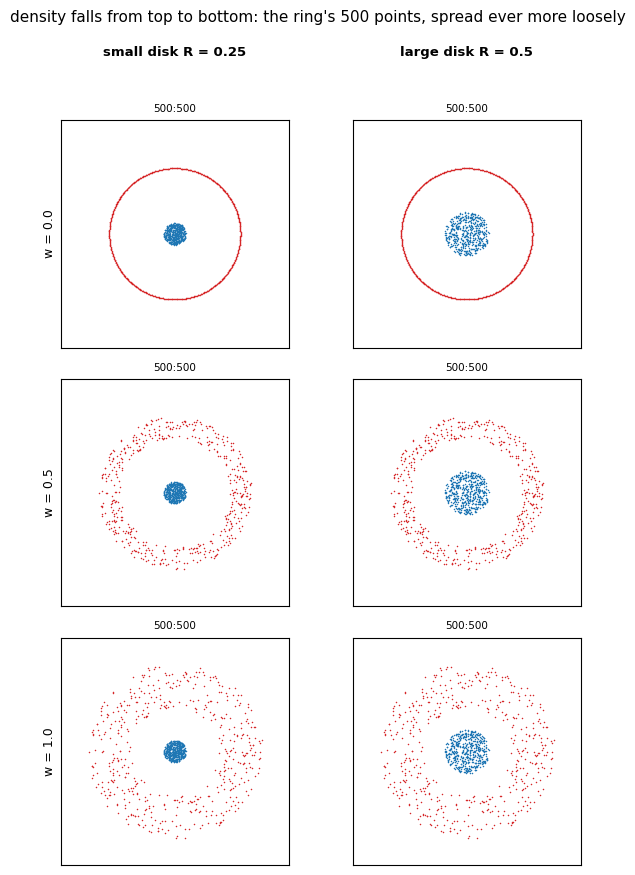

In [2]:
# Three ring widths and two disk radii at 500:500. Between the panels of a row the number of points
# does not change — only the area they are spread over does.
show = [n for w in W3 for R in (0.25, 0.5) for n in C(task="relevant", w=w, R=R, rho=1.0, T=1000)]
fig = dplt.plot_dataset_grid(show, dsw.dataset_points, ncols=2, size=2.7,
                             xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), label_of=label,
                             row_labels=[f"w = {w}" for w in W3],
                             col_labels=["small disk R = 0.25", "large disk R = 0.5"],
                             title="density falls from top to bottom: the ring's 500 points, spread ever more loosely")
plt.show()

### One quantitative anchor — and after that only "denser / sparser"

Density as a number is not needed in this experiment: all statements below are qualitative, of the form "it became
sparser — did anything change". But one anchor is useful to have, to understand **in what range the sweep works
relative to the instrument itself**. Let us take the mean distance between neighbouring points of the ring and
compare it with the step of the grid on which the level sets are computed.

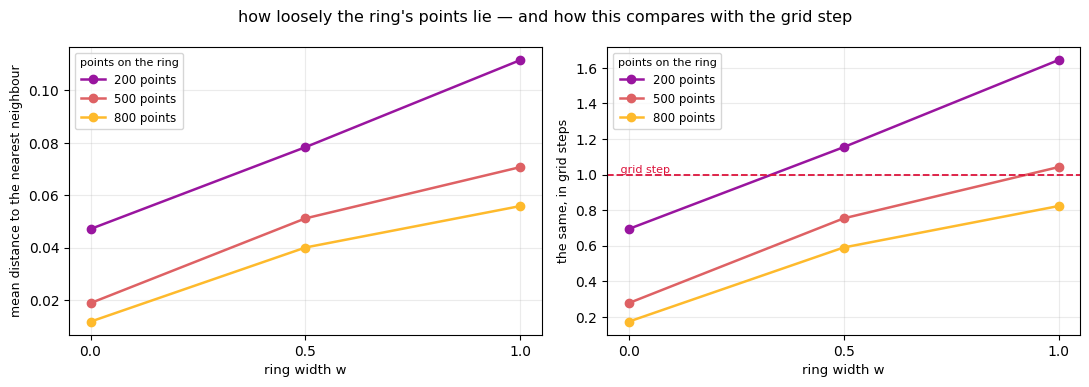

In [3]:
sp = dsw.spacing_table(REL)
ring = sp[sp["object"] == "ring"].drop_duplicates(["w", "n_ring"])
fig = dplt.plot_spacing(ring, GRID_STEP,
    title="how loosely the ring's points lie — and how this compares with the grid step")
plt.show()

### What we see

**The sweep carries the sample across the resolution of the instrument — at the number of points we chose.**
Both ends of the axis depend on the width as well as on the number of points: with 500 points on the ring the distance
to the neighbour goes 0.019 → 0.051 → 0.071 over the three widths, that is, from three times denser than the grid
step to level with it; with 200 points the whole line is shifted up and already at `w = 0.5` lies sparser than the
grid. What matters is that the range is chosen meaningfully: if the density of the training points influenced
anything at all, it would have to show up here.

**This distance is about the data, not about the instrument.** Further on a similar quantity `δ(A)` will appear —
the spacing of the **target** against which the score is computed, and it has its own, separate condition relative to
the grid step (§2.1). The two must not be confused: here we measure the manipulated variable of the experiment, there —
the resolving power of the instrument.

**The steps of the axis are unequal.** The transition `w = 0 → 0.5` thins the points more than `0.5 → 1.0` (the area
grows linearly, and the distance between points as a square root). So along this axis one should read the **presence
and the sign** of an effect, not its slope.

From here on the word "density" is used in its ordinary sense — how tightly the points of an object lie — and all
conclusions about it are qualitative.

---

## 1.1 Are these datasets really task-relevant?

Before measuring anything on networks, it is worth making sure that there is something to measure. We call half of
the configurations task-relevant by construction — a ring around a disk of the opposite class — but this is a
statement **about the data**, and it has to be checked rather than assumed.

**There is a check, and it does not require a single trained model.** The chromatic alpha complex is built on the
coloured point cloud itself. The quantity of interest is the **kernel** of the map from the subcomplex of class 0
(the ring) into the full complex: a cycle of ring points that **dies** as soon as the disk points are added. That is,
a hole of one class filled by the other — exactly the definition of a task-relevant topological feature
(Section 4.2 of the paper).

This is a ground truth lying one level below the neural network: it says whether the feature is present in the task,
regardless of whether any model has found it.

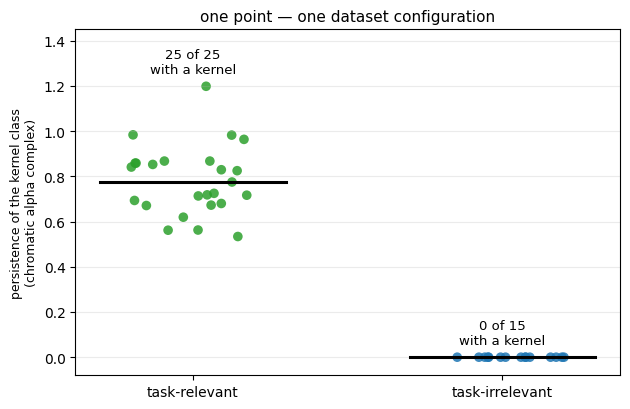

               min  median     max
task                              
irrelevant  0.0000  0.0000  0.0000
relevant    0.5337  0.7748  1.1982


In [4]:
chrom = dsw.chromatic_task_relevance(sorted(cells.cell.unique()))
fig, ax = plt.subplots(figsize=(6.4, 4.2))
rng = np.random.default_rng(0)
for i, (task, colour) in enumerate((("relevant", dplt.CT), ("irrelevant", dplt.C1))):
    v = chrom[chrom.task == task]["kernel_persistence"].to_numpy()
    ax.scatter(i + rng.uniform(-.2, .2, len(v)), v, s=48, color=colour, alpha=.85,
               edgecolors="none")
    ax.plot([i - .3, i + .3], [np.median(v)] * 2, color="k", lw=2.2, zorder=5)
    ax.text(i, max(v) + .06, f"{(v > 0).sum()} of {len(v)}\nwith a kernel", ha="center", fontsize=9.5)
ax.set_xticks([0, 1]); ax.set_xticklabels(["task-relevant", "task-irrelevant"], fontsize=10)
ax.set_ylabel("persistence of the kernel class\n(chromatic alpha complex)", fontsize=9)
ax.set_ylim(-0.08, 1.45); ax.grid(alpha=.25, axis="y")
ax.set_title("one point — one dataset configuration", fontsize=11)
plt.tight_layout(); plt.show()

print(chrom.groupby("task")["kernel_persistence"].agg(["min", "median", "max"]).round(4).to_string())

### What we see

**The ground truth separates our datasets cleanly.** A persistent kernel class is present in **25 configurations of 25**
task-relevant ones and **in none of the 15** task-irrelevant ones: in the latter the persistence is exactly zero, while
in the former it lies in 0.53–1.20. There is no intermediate zone.

**This will be needed twice.** First, all 25 relevant configurations are **positive examples**, and a failure of the
detector to fire on any of them is an error, not information; the choice of the target will rest on this (§2.6).
Second, all 15 irrelevant ones are **negative**, and this makes task A a measurement rather than an assumption.

**One observation that should not be overrated.** The persistence varies among the relevant configurations
(0.53–1.20). It is tempting to read this as a "degree of relevance", but the quantity is expressed in the units of
the alpha filtration, that is, in squared length, and it falls as the ring widens simply because the inner radius —
and with it the hole itself — shrinks. The difference here is mainly geometric, and further on only its binary part
is used: the kernel is there or it is not.

---

# 2. Task D — relative to what the structural score is computed

**Question.** The structural criterion compares a level set of a neuron with the **target** `A` and returns
`Chamfer distance / diameter of A`. As long as the feature was a circle, the target was defined uniquely. As soon as
it became a ring, this stopped being so: one can take the ring itself as the target, or any circle inside it. All the
numbers of tasks A–C depend on the choice, so it is made here, and first.

**The frame that holds the whole section.** A null feature is a negative control, and it belongs to a **specific
dataset configuration**: to its 50 models, its geometry, its field. So distributions are considered only within one
configuration, and every summary number below is a **median of per-configuration quantities**, not a quantity
computed on pooled data.

**Order of presentation.** First, what a target is at all and how finely it has to be sampled (§2.1), then the nulls,
which have only one free parameter (§2.2), then the data, configuration by configuration (§2.3). After that, two
questions about the fairness of the comparison: whether the targets are equally attainable (§2.4) and how well each one
distinguishes the target from its own floor (§2.5). At that point the target is chosen (§2.6) — and only after that is
the threshold set (§2.7), because the choice of target rests on no threshold. The section ends with a by-product of
the four targets (§2.8) and the second condition of the verdict (§2.9).

## 2.1 What a target is

### A target is a sample of a region of space, not the training data

This is the most important thing for understanding what exactly we measure, and it is worth pausing on.

**We measure not which places of the training sample the neuron pays attention to, but whether its level set agrees
with the region of space that we have decided to interrogate.** The region may coincide with the one where the data
lie, or it may not; and we are entitled to sample its points ourselves, to get more accurate representatives of it
than the training cloud would give.

That is exactly the case in this experiment. The three concentric circles — along the inner edge of the ring, along its
midline and along its outer edge — **do not exist in the data at all**. The dataset has a ring; the circles were built
by us on purpose, to ask **at what radius** the level sets lie. Nothing is smuggled in this way: the criterion asks
whether the level set agrees with a region that we have **named**, and naming it is our right.

This is precisely what makes the question meaningful beyond clean synthetic data. On noisy or real data there is no
generating curve, and the question "does the neuron encircle the object" would hang without a referent. But the
question "does the level set agree with this region more strongly than with the same region placed elsewhere" does not
hang, and it can be answered with nothing but the region itself and its rigid motions.

Hence the number of points in a target as well: it is **our decision**, the same in all forty configurations (500 per
circle, 1000 per ring), and not a reflection of how densely the data occupy this region. How finely this region has to
be resolved is a separate question, and it has an exact answer.

### Four candidates and the motives for them

| candidate | motive |
|---|---|
| **ring** `t_ring` | the most honest: the feature is the ring, no additional engineering |
| **middle circle** `t_mid` | substituting a circle for the ring introduces a bias; of all circles, it is minimised by the one closest to the ring — and that is this one |
| **inner circle** `t_inner` | if a relevant topological feature is formed in equal measure by the feature and its interior of the opposite class, then one should look at the zone of their interaction — at the inner edge |
| **outer circle** `t_outer` | has no motive of its own; it is needed as a **bracket**, to see whether the score is monotone in the probing radius |

All four are computed on **the same models** in each configuration, so the comparison between them is not confounded by
anything. At `w = 0` all three circles **coincide** — there they are one and the same feature — and such cells are not
considered in this section.

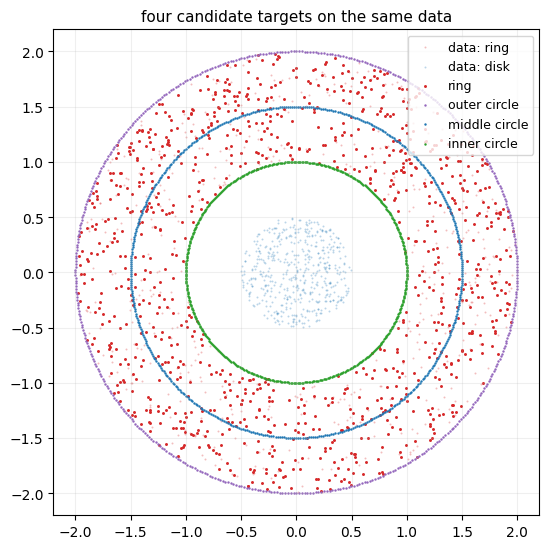

In [5]:
fig = dplt.plot_target_shapes(dsw.dataset_points, "d4_rel_w10_R050_r100_T1000")
plt.show()

### How finely the target must be sampled: the condition `δ(A) < h`

Let `δ(A)` denote the typical distance between neighbouring points of the **target**, and `h = 0.0679` the step of the
grid on which the level sets are extracted. (This is not the quantity of §1: there the distance was measured between
points of the **data**, here between points of the target.)

The first term of the Chamfer distance, `mean_{c∈C} d(c, A)`, has a **lower bound**: a point lying **exactly on** the
region will still find the nearest **sampled** point about `δ/2` away — simply because there is nothing between the
sampled points. A level component has a lower bound of its own, `≈ h/2`: it cannot be localised more finely than the
grid step. The two sources are independent, so the best attainable distance is about

```
sqrt( (h/2)² + (δ(A)/2)² )
```

and the discretisation of the target is harmless exactly when `δ(A) < h`. Above that, **the measuring ruler is coarser
than what it measures**, and the score stops speaking about the network.

The formula is not postulated: in §2.4 the attainable scores are measured directly, by feeding the criterion the field
that an ideal detector of each shape would have. Here is its prediction next to that measurement — the column
"predicted" is obtained by the formula above, the column "measured" is taken from §2.4:

| target | `δ(A)` | `δ/h` | predicted by the formula | measured in §2.4 |
|---|---|---|---|---|
| circle `r = 1.0`, 500 points | 0.0126 | 0.19 | 0.0345 | **0.0337** |
| circle `r = 1.5`, 500 points | 0.0188 | 0.28 | 0.0352 | **0.0342** |
| circle `r = 2.0`, 500 points | 0.0251 | 0.37 | 0.0362 | **0.0360** |
| **ring, 1000 points** | **0.097** | **1.43** | 0.0592 | **0.0491** |

For the circles the agreement is in the third decimal — the model is right. The ring, however, is the only one with
`δ/h > 1`, and the reason is clear: the same thousand points have to cover an **area**, not a curve, so `δ = sqrt(S/n)`
is inevitably coarser. The ring is limited by its own sample, not by the grid.

### Two consequences worth writing down

**The target must not be allowed to follow the data.** If one takes `A` = the points of the dataset, then for the ring
`δ = sqrt(area/n)`, and `n` is the `ρ` axis, a manipulated variable of the experiment. The instrument would measure
sparse cells with a coarser ruler than dense ones: at `ρ = 0.25` (200 points) one would get `δ/h = 3.2`, three times
beyond the limit of applicability, and precisely in the cell where we find the worst result.

**Densifying the ring's reference is no way out either.** It is tempting to decide that the ring is simply undersampled
and would turn out to be a better target with a denser reference. Measured: when the reference is changed sixteenfold
(250 → 4000 points) the median score does not move at all (0.3778 → 0.3800), and the best neuron improves by 6% —
while the discriminating power of the ring is 1.57 against 2.32 for the middle circle and 4.79 for the inner edge
(§2.5), that is, the lag there is incomparably larger.
The reason is that the lower bound of the ring (0.049) is eight times below its own typical score (0.414): the
discretisation constrains only the best neurons, while it is the typical ones that discriminate.

This is a rule of the whole project (Section 5.2 of the paper): if an object exists in the data and its own
sample is coarser than the grid, one has to either refine the grid or say honestly that this grid does not resolve the
object.

## 2.2 Nulls: the same targets, moved

A score means nothing by itself: whether 0.15 is good or bad depends on what it costs to get 0.15 by chance. A floor
is needed, and it is given by the **nulls** (the negative control, Section 6.2 of the paper).

**A null has exactly one free parameter — its place.** Everything else is set by the target: a null is **the very same
shape**, of the same size, with the same number of points, moved by a rigid motion to where the task requires nothing.
Checked on the data: the point counts coincide in all configurations and on all four targets, and after aligning the
centres the clouds of the target and the null differ by 3·10⁻⁷ — float32 round-off. Nor could it be otherwise: if a
null differed from the target in anything other than position, the contrast "target against floor" would stop
isolating position.

**But the place is chosen, and here is how.** There are three placements, and they **do not move between cells**: two
far from the decision boundary in different directions (`far_right` at `(4.5, 0)`, `above_target` at `(0, 4.5)`) and
one in the corridor at the boundary (`in_corridor` at `(−3.5, −3.0)`) — the last only in task-irrelevant cells, where
the corridor exists. Experiment 1 measured that the floor depends substantially on the place, so a moving placement
would make the floor incomparable along the sweep.

**A consequence that has to be named:** on the task-relevant side there are **two** placements, and it is precisely
there that the verdict is delivered.

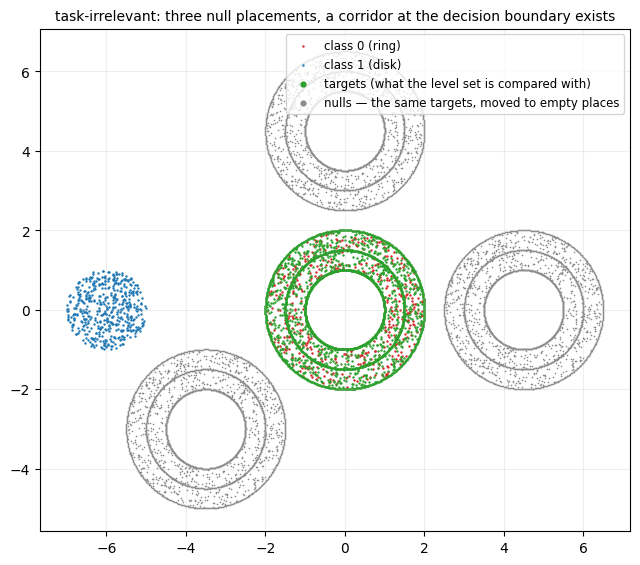

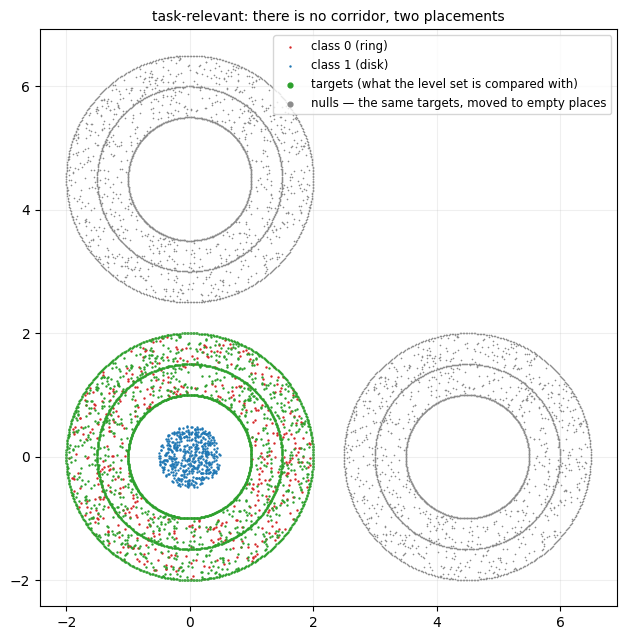

In [6]:
for cell, title in (("d4_irr_w10_R100_r100_T1000",
                     "task-irrelevant: three null placements, a corridor at the decision boundary exists"),
                    ("d4_rel_w10_R050_r100_T1000",
                     "task-relevant: there is no corridor, two placements")):
    fig = dplt.plot_targets_and_nulls(cell, dsw.dataset_points, title=title)
    plt.show()

## 2.3 All configurations separately

The targets and the floor are defined — now we can look at the data. The four figures below show **everything**, and
the rest of the section rests on them.

A row is one dataset configuration (the configuration itself is drawn on the left), a column is one target. Each panel
shows **the whole population**: nulls in grey on top, the target in colour below, medians as ticks. The number **×N**
says how many times the target's median is better than the median of its nulls; this is a dimensionless separation,
and it does not depend on any threshold. The red dotted line is the threshold, and the number **fraction** is the
fraction of models that passed it; **the choice of the threshold's level is justified later, in §2.7**; here it is
needed only as a guide.

The figures are split into four blocks by task and ring width: precisely these two coordinates change the geometry of
the targets and the nulls. Within a block, the rows are the disk radius, the balance and the sample size.

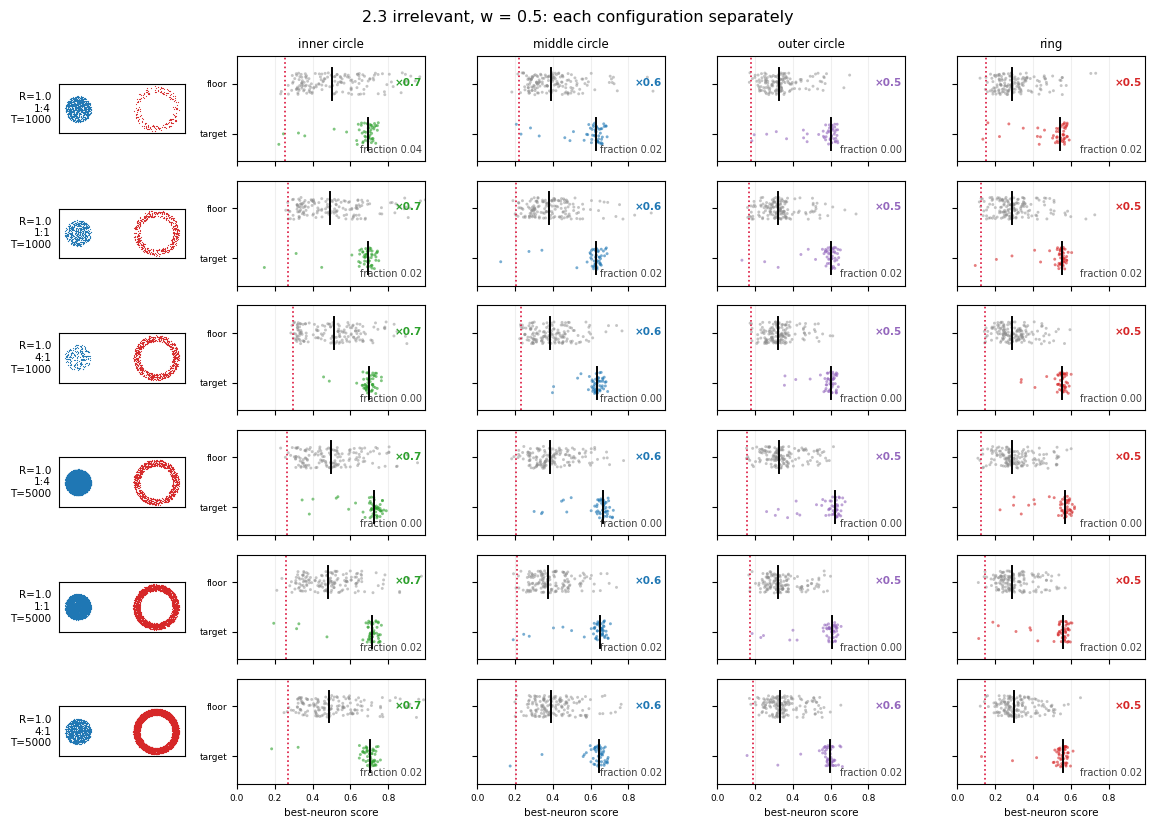

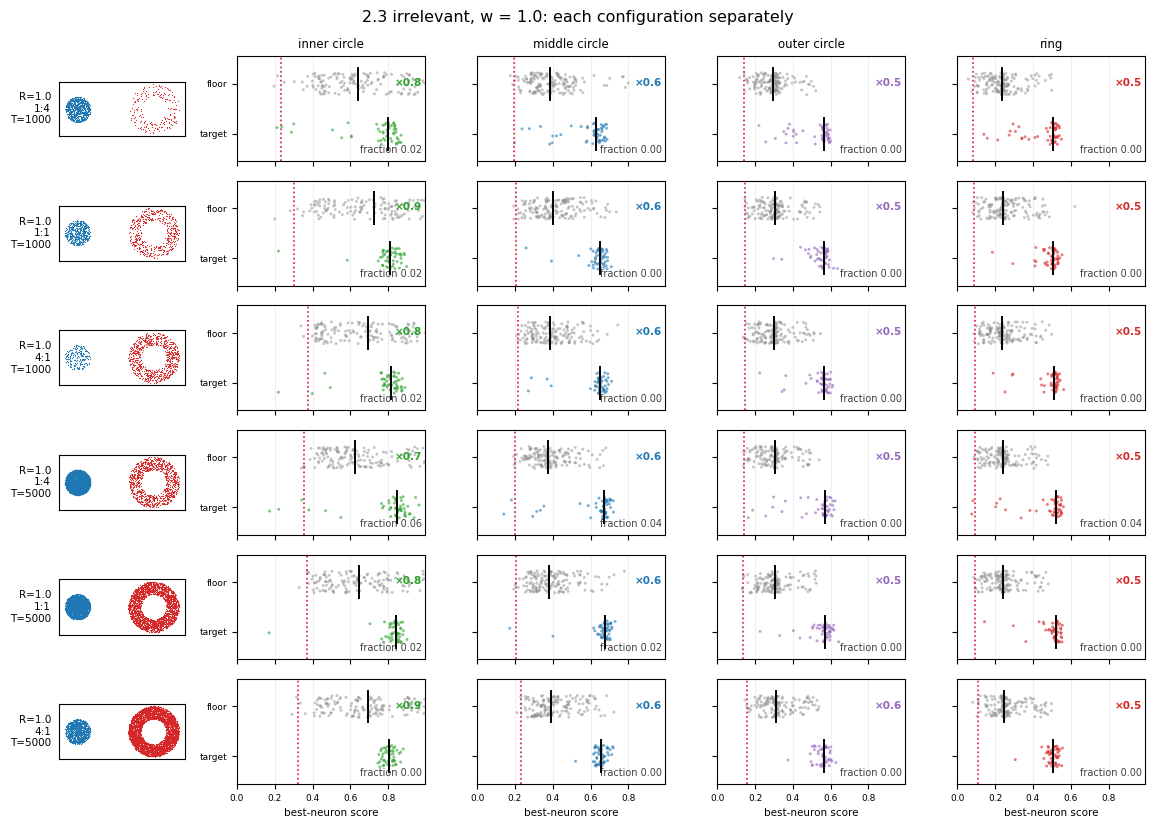

In [7]:
BLOCKS = []
for task in ("irrelevant", "relevant"):
    for w in (0.5, 1.0):
        names = [n for n in sorted(cells.cell.unique())
                 if dsw.cell_of(n)["task"] == task and dsw.cell_of(n)["w"] == w]
        names.sort(key=lambda n: (dsw.cell_of(n)["T"], dsw.cell_of(n)["R"], dsw.cell_of(n)["rho"]))
        BLOCKS.append((f"{task}, w = {w}", names))
XMAX = float(np.quantile(best[best.w > 0].score.dropna(), 0.995))
for name, names in BLOCKS[:2]:
    fig = dplt.plot_config_panels(names, best, cells, dsw.dataset_points, xmax=XMAX,
        row_label=row_label, title=f"2.3 {name}: each configuration separately")
    plt.show()

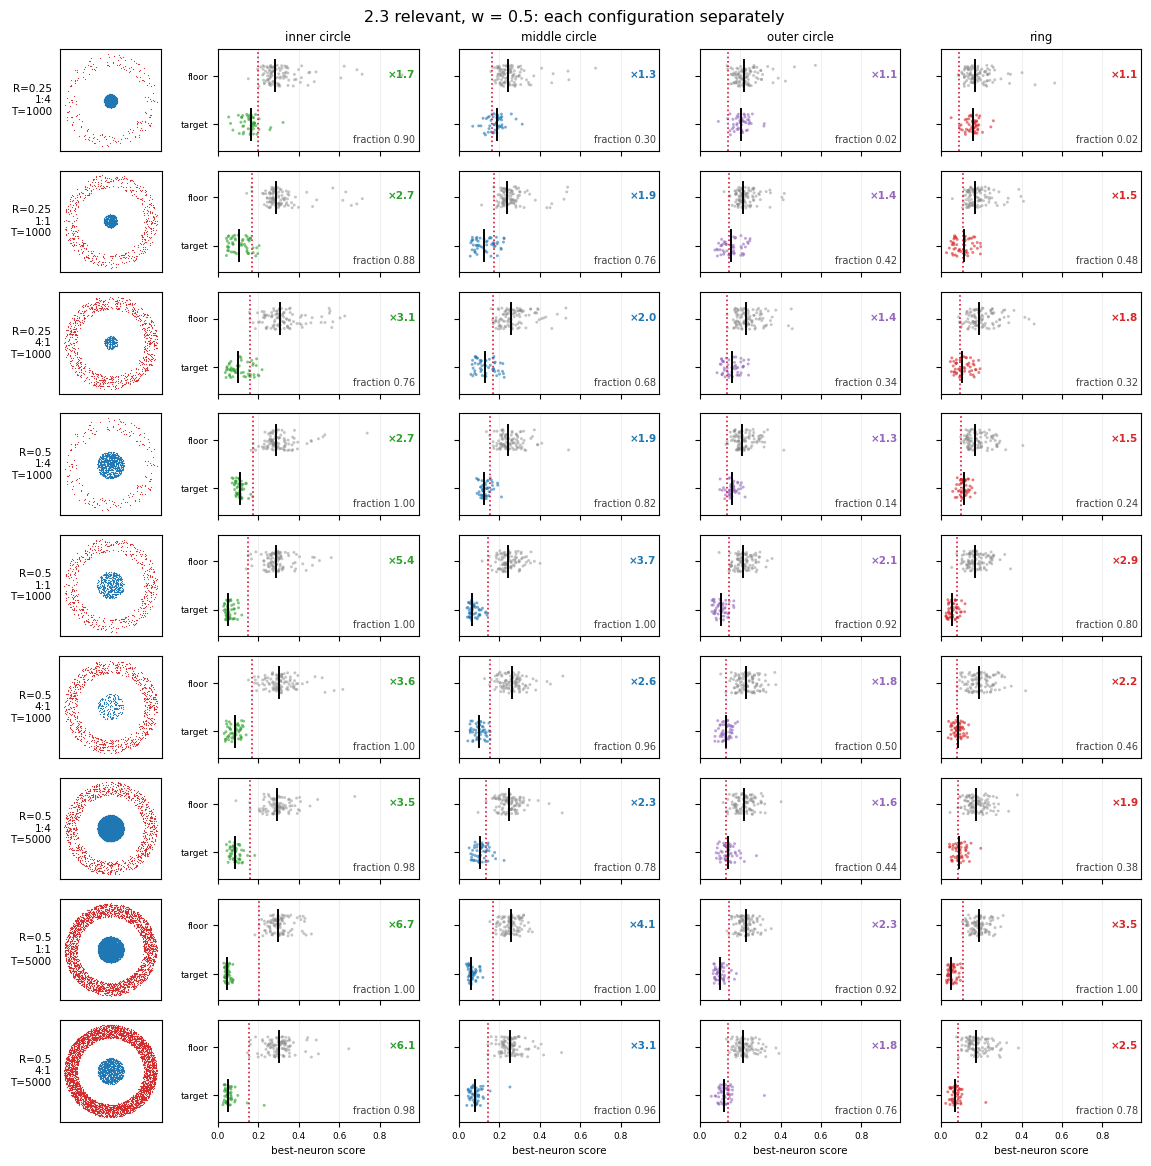

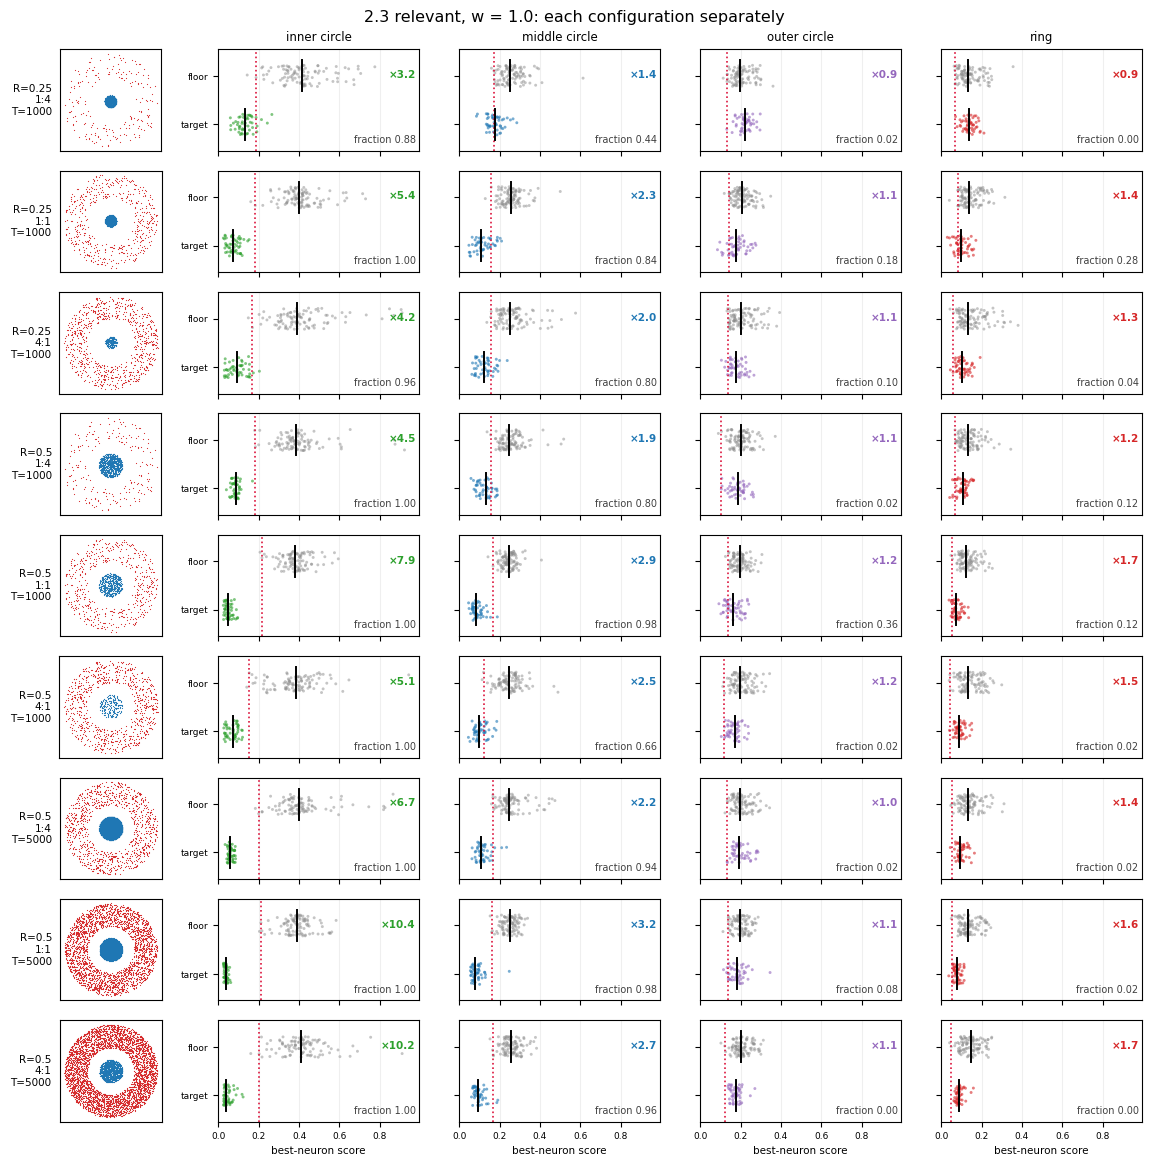

In [8]:
for name, names in BLOCKS[2:]:
    fig = dplt.plot_config_panels(names, best, cells, dsw.dataset_points, xmax=XMAX,
        row_label=row_label, title=f"2.3 {name}: each configuration separately")
    plt.show()

### What we see

**The picture is the same in all configurations within a task and opposite between the tasks.** In the irrelevant
blocks the target lies **to the right** of its nulls in all twelve configurations and on all four targets; in the
relevant ones it lies to the left, also everywhere. The conclusion holds not on average but in each configuration
separately.

**The separation of target and floor is distributional, not complete.** Within a configuration the tail of the target
enters the territory of the nulls: on the middle circle the worst model is worse than the best null in 17 relevant
configurations of 18. On the inner edge — which is to become the verdict target — this happens in only 8 of 18, but
even there the separation is not complete. So the correct formulation is not "the target does not overlap the floor"
but "`p_superior` = 0.87–1.00 across configurations" (0.97–1.00 on the inner edge).

**The targets line up in a stable hierarchy, and it can be read directly off the ×N numbers.** The order
**inner → middle → ring → outer** holds at both widths, and it stretches as the width grows: the inner one improves, the
outer one sinks almost to chance, the middle one stays where it is. The values are analysed in §2.5.

## 2.4 Are the targets equally attainable?

§2.1 gave the condition `δ(A) < h` and predicted what score is attainable on each target. Now this is measured
directly, and the prediction itself is checked along the way.

The criterion accepts an arbitrary function, so it can be fed **the field of an ideal neuron** of each shape to see what
score comes out: `|x|` for a circle (its level sets are exactly concentric circles), the plateau
`tanh(k(r−r_in)) − tanh(k(r−r_out))` for the ring, and the limiting case `−dist to the ring`. The best result over this
family is what is called the **ceiling** here.

**A caveat about the word "ceiling".** It is not a proven lower bound but the best of several fields built by hand for
each shape. Experiment 1 has already shown once that a planted construction need not be optimal: the "best" value
claimed there was later beaten by ordinary neurons. So the correct formulation is "attainable no worse than", and it is
needed only to compare the targets with each other, not as a theorem about a limit.

**Why a plateau for the ring and not a circle.** A level component is extracted as `{x : |f − c| ≤ ε}`, where `ε`
under `level_eps="adaptive"` is a quantile of the value jumps between neighbouring grid nodes near the target. On a
sloped field this gives a band about two grid steps wide — a narrow one, and it cannot cover a ring of width 1.0. But
if the field is **saturated** on the ring, that is, almost constant there, the jumps are small, and the set
`|f − c| ≤ ε` covers the whole annular layer. A plateau is exactly a saturated field.

### In what units to read the ceiling

An ideal field leaves a discrepancy set by the **grid step** — an absolute quantity that knows nothing about the
target. The score, however, is `Chamfer / diam(A)`. So the normalised ceiling **must** fall as `1/diam` — this is
arithmetic, not geometry: for circles of radius 1.0, 1.5 and 2.0 against a dense reference the absolute ceiling stays
within 3% of `h/2 = 0.0339`, while the normalised one goes 0.0167 → 0.0112 → 0.0087, exactly in the ratio of the
diameters.

**Hence the rule:** targets of different size **cannot** be compared by the raw normalised score — neither the targets
nor the ceilings. Only dimensionless ratios are comparable: "floor / target" (§2.5) and "achieved / ceiling" (here). In
both, the diameter cancels.

**And one subtlety that had to be cleaned out.** The levels are scanned with a grid of 101 values over the range of the
field — for `|x|` on our box that is a step of 0.106, three times coarser than the grid step. Where the target's radius
falls between two nodes is a lottery, and it added up to 49% to the measured ceiling of the outer circle. Below, the
ceiling is measured at the **exact level**; the experiment itself runs at 101 levels and pays this lottery on a par
with all the neurons.

**What is compared with the ceiling.** The trained neurons of **one and the same configuration**: the task within it is
fixed, the models are the same, they are evaluated by the same 1250 neurons (50 models × 25) — only the target changes.
Two quantities are shown: **the best neuron** (the minimum over all 1250) says what the network achieves in principle,
**the median of the per-model best** says what a typical model achieves.

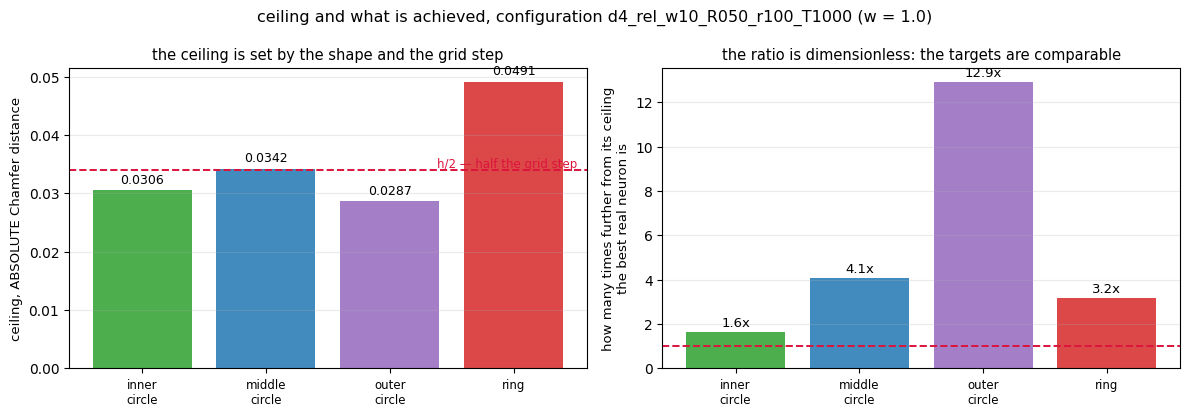

In [9]:
CEIL_CELL = "d4_rel_w10_R050_r100_T1000"          # w = 1.0, the widest ring
ceil = dsw.ceiling_probe(CEIL_CELL)               # exact level, absolute units

sub = df[(df.dataset_type == CEIL_CELL) & (df.feature_role == "target")]
real_best = sub.groupby("family").score.min()
real_med = (sub.groupby(["family", "model_path"]).score.min().groupby("family").median())

fig = dplt.plot_ceiling(ceil, real_best=real_best, grid_step=GRID_STEP,
    title=f"ceiling and what is achieved, configuration {CEIL_CELL} (w = 1.0)")
plt.show()

### What we see

**The three circles are equally attainable, and the prediction of §2.1 is confirmed.** The measured ceilings are
0.0337 / 0.0342 / 0.0360 at `h/2 = 0.0339` — a spread of 7%, and all three lie within the third decimal of what the
formula gives. The field `|x|` is the same for all three radii, so if the ceilings had diverged, the cause would have
been the construction of the planted field, not the target. They do not diverge.

**The ring, however, has a higher ceiling — 0.0491 against 0.034, that is, 45% higher.** So one cannot claim "no
target is intrinsically harder": the ring is harder, and this has to be named. But the cause is named and measured: it
has `δ/h = 1.43`, that is, its own sample is coarser than the grid, because the same thousand points cover an **area**,
not a curve. The difference is explained entirely by the discretisation of the target and says nothing either about
the network or about whether the ring is harder for it.

**And this does not affect the comparison, because each target is compared with ITS OWN floor.** The quantity "floor /
target" is dimensionless and, within one target, is formed from the same units, so the higher ceiling of the ring does
not enter it. This is exactly why the targets are comparable despite their different ceilings.

**The shape of the ideal field confirms the mechanism.** The ring is caught best by the plateau of steepness 8
(0.0491), and four times worse by the thin circle `|x|` (0.213). The middle circle is the opposite: `|x|` gives 0.0342,
the plateaus 0.092–0.161. At steepness 32 the plateau breaks down: its edge becomes thinner than the grid step.

**Both estimates of what is achieved give the same order.** By the best of 1250: inner 1.6×, ring 3.2×, middle 4.1×,
outer 12.9×. By the median of the per-model best: 3.2× / 6.1× / 7.3× / 22.9×.

**The strongest observation concerns the outer circle.** Its ceiling is no worse than the others (0.0287 absolute),
that is, it is no harder at all to reproduce. Yet the real neurons stand 12.9 times away from it, against 1.6 for the
inner one. So the cause is not the difficulty of the target.

**And a divergence of the two dimensionless measures that is worth naming.** By "achieved / ceiling" the ring (3.2×)
turns out **better** than the middle circle (4.1×), while by "floor / target" (§2.5) it is worse. There is no
contradiction: the first measure says how close the network has come to the ideal detector of this shape, the second
how much the target differs from chance. **The choice of target needs the second**, because a detector is valuable for
its discrimination, not for its absolute accuracy.

## 2.5 Discriminating power

The measure is dimensionless: **how many times the target's median is better than the median of its nulls in the same
configuration**. The diameter of the target cancels in this ratio, so it is the same in any units, and it requires no
threshold. It is computed in each configuration separately and only then summarised.

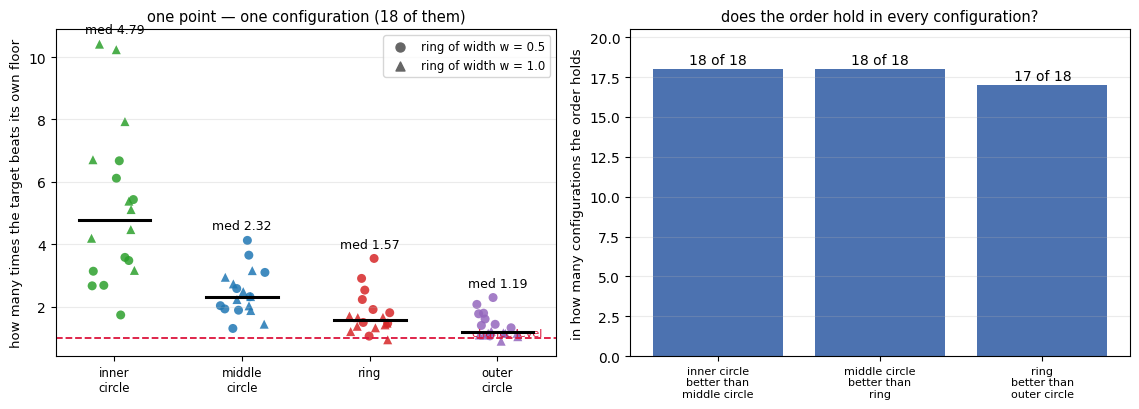

In [10]:
disc_cell = []
for (ds, fam), g in best[(best.task == "relevant") & (best.w > 0)].groupby(["dataset_type", "family"]):
    t = g[g.feature_role == "target"].score.median()
    n = g[g.feature_role == "null"].score.median()
    disc_cell.append({"cell": ds, "family": fam, "w": dsw.cell_of(ds)["w"], "floor/target": n / t})
disc_cell = pd.DataFrame(disc_cell)

fams = ["t_inner", "t_mid", "t_ring", "t_outer"]
MARK = {0.5: "o", 1.0: "^"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
rng = np.random.default_rng(0)
for i, fam in enumerate(fams):
    for w, mk in MARK.items():
        v = disc_cell[(disc_cell.family == fam) & (disc_cell.w == w)]["floor/target"].to_numpy()
        ax1.scatter(i + rng.uniform(-.18, .18, len(v)), v, s=42, marker=mk,
                    color=dplt.FAM_COLOUR[fam], alpha=.85, edgecolors="none")
    allv = disc_cell[disc_cell.family == fam]["floor/target"].to_numpy()
    ax1.plot([i - .28, i + .28], [np.median(allv)] * 2, color="k", lw=2.2, zorder=5)
    ax1.text(i, allv.max() + .35, f"med {np.median(allv):.2f}", ha="center", fontsize=9)
for w, mk in MARK.items():
    ax1.scatter([], [], marker=mk, s=42, color="0.4", label=f"ring of width w = {w}")
ax1.axhline(1.0, color="crimson", ls="--", lw=1.3)
ax1.text(.98, 1.0, "chance level ", transform=ax1.get_yaxis_transform(),
         ha="right", va="bottom", fontsize=8, color="crimson")
ax1.set_xticks(range(len(fams)))
ax1.set_xticklabels([dplt.FAM_LABEL[f].replace(" ", "\n") for f in fams], fontsize=8.5)
ax1.set_ylabel("how many times the target beats its own floor", fontsize=9.5)
ax1.set_title("one point — one configuration (18 of them)", fontsize=10.5)
ax1.grid(alpha=.25, axis="y"); ax1.legend(fontsize=8.5)

piv = disc_cell.pivot(index="cell", columns="family", values="floor/target")
pairs = [("t_inner", "t_mid"), ("t_mid", "t_ring"), ("t_ring", "t_outer")]
vals = [int((piv[a] > piv[b]).sum()) for a, b in pairs]
ax2.bar(range(len(pairs)), vals, color="#4c72b0")
for i, v in enumerate(vals):
    ax2.text(i, v + .3, f"{v} of {len(piv)}", ha="center", fontsize=10)
ax2.set_xticks(range(len(pairs)))
ax2.set_xticklabels([f"{dplt.FAM_LABEL[a]}\nbetter than\n{dplt.FAM_LABEL[b]}" for a, b in pairs], fontsize=8)
ax2.set_ylim(0, len(piv) + 2.5)
ax2.set_ylabel("in how many configurations the order holds", fontsize=9.5)
ax2.set_title("does the order hold in every configuration?", fontsize=10.5)
ax2.grid(alpha=.25, axis="y")
plt.tight_layout(); plt.show()

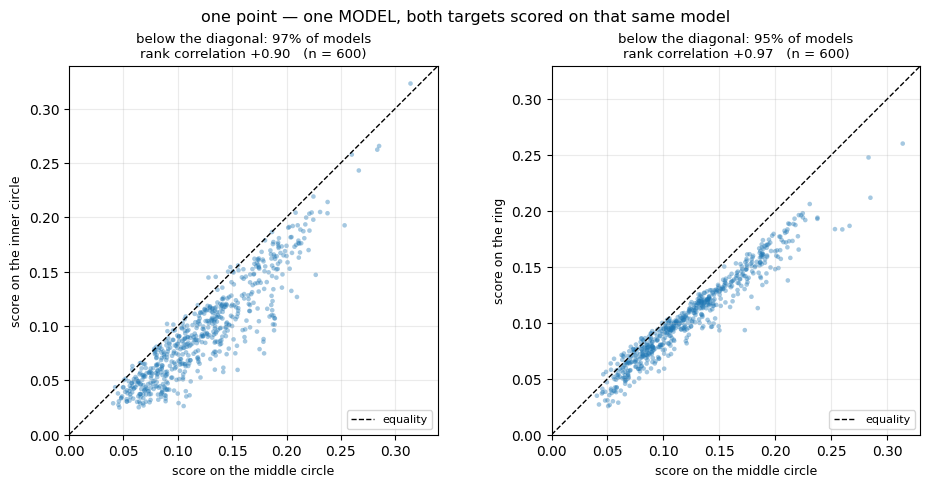

In [11]:
REL12 = [n for n in REL if dsw.cell_of(n)["w"] > 0]
fig = dplt.plot_paired_scatters(best, [("t_mid", "t_inner"), ("t_mid", "t_ring")], cells=REL12,
    suptitle="one point — one MODEL, both targets scored on that same model")
plt.show()

### What we see

**The order of the targets is the same in EVERY configuration, not on average.** The inner circle discriminates better
than the middle one in 18 configurations of 18, the middle one better than the ring in 18 of 18, the ring better than
the outer one in 17 of 18. The conclusion does not depend on which configurations happened to be in the sample.

**The values: a median of 4.79 for the inner circle, 2.32 for the middle one, 1.57 for the ring, 1.19 for the outer
one.** The spread across configurations is large (1.73–10.41 for the inner one), but the ranges barely overlap with
their neighbours. **The outer circle is in places worse than chance** (a minimum of 0.89) — this is no longer a weak
target but a non-working one.

**The ring width pulls the targets apart rather than shifting them together.** For the inner circle the triangles
(`w = 1.0`) lie noticeably above the round markers (`w = 0.5`), and for the outer one below them: the wider the ring,
the more its inner and outer edges diverge as targets, while the middle circle does not move.

**The targets are strongly correlated across models, but not interchangeable.** The rank correlation of the scores is
0.90 and 0.97: a model that is good on one target is good on the other as well — a model's "goodness" is a general
property of it. But **at which radius exactly** it is good does not change from model to model: the inner circle gives
a better score than the middle one for 97% of the models, and the outer one for only 1%. That is, all models are good
at one and the same radius and differ only in how good they are.

**The ring loses because of its FLOOR, not because of its target.** In absolute units — the only ones in which targets
of different size are comparable — the target median is 0.376 for the ring and 0.325 for the middle circle, that is,
the ring is even worse. But the floor of the ring is 0.631 against 0.750: a random component comes noticeably closer to
a wide band than to a thin circle. The target is not better, the floor is better — hence the smaller ratio.

## 2.6 The choice of the target

Everything needed has been collected, and none of the three supports requires a threshold.

**The first support is the ground truth (§1.1).** All 25 task-relevant configurations are indeed task-relevant at the
level of the data, and all 15 irrelevant ones are indeed not. So each relevant configuration is a **positive example**,
and weak discrimination on it is an error of the target, not a property of the task.

**The second support is the discriminating power (§2.5).** The median of the ratio "floor / target": **4.79** for the
inner circle, 2.32 for the middle one, 1.57 for the ring, 1.19 for the outer one. The inner one is better than **each**
of the other three, and the order holds in each of the 18 configurations separately.

**The third support is the distance to the target's own ceiling (§2.4).** The best neuron stands **1.6 times** away
from the ceiling of its target for the inner circle, against 3.2 for the ring, 4.1 for the middle one and 12.9 for the
outer one. Here too the inner one is better than all three others, and the ceilings of all four are practically the
same, so the comparison is fair.

**The verdict is carried by the inner circle `t_inner`.** It wins by both independent measures, and it alone has a
substantive motive, named before any computation: if a relevant topological feature is formed by the pair "feature +
interior of the opposite class", then the zone of their contact is what should be at work.

**The ring and the outer circle do not enter the verdict.** The ring's discriminating power is 1.57: a wide band is easy
to cover by chance, and this helps the null no less than the target. The outer one has 1.19, and in places below one —
that is, worse than chance. They have no role of their own except that of a distant probe in §2.8.

**The middle circle stays needed for exactly one thing — to be a STATIONARY probe.** The radius of the inner edge
**moves together with `w`**: 1.5 → 1.25 → 1.0 over the three widths. So along the width axis the two targets answer two
different questions, and both are needed: the stationary middle circle asks "does the picture at a fixed place
deteriorate because the points lie sparser", while the inner edge, which moves together with the feature, asks "does
the network's structure follow the edge of the feature". The first question is about density, the second about
geometry, and in §4.1 they are separated.

One technical consequence: since the diameter of the inner edge changes along this axis, the normalised score there has
to be read with a correction — it is shown together with the dimensionless ratio **"floor / target"**, in which the
diameter cancels. Which way the normalisation pulls is known in advance: the ceiling `h/2 / diam(A)` grows as the
target shrinks, that is, the normalisation makes things harder, not easier (§2.4).

The target is chosen. Now the threshold can be set.

## 2.7 The threshold, and what "witness fraction" means

Up to now everything was computed on the scores themselves, and the threshold was not needed even once. But the
verdict "the neuron witnesses" is binary, and tasks A–C need it.

For one (model, target) pair we take **the best of the model's 25 neurons** — the one with the smallest score. A model
is considered **witnessing** if this best score does not exceed the threshold. The **witness fraction** is the fraction
of such models among the 50 in the configuration.

The threshold is computed **in its own configuration and for its own target**: we take the scores of **all** of that
target's nulls in the same place (50 models × the number of placements, that is, 100–150 values) and take their
**null percentile**. No splitting of the sample: the threshold is set on the whole floor that this configuration has.

Why not τ = 0.1 from experiment 1: that number was tuned for a circle target of radius 1.5 in a different box. Here the
thresholds of the inner circle run 0.150–0.216 across configurations, those of the middle one 0.120–0.195 — τ = 0.1
comes close to none of them and would mean different things in different cells, so from here on it is not used —
neither as a threshold nor as a mark on the plots.

**The level is chosen by the inner circle** — by the target that carries the verdict (§2.6). The other three get the
same rule: they are worse, and tuning the instrument to the weakest one would mean choosing it for the wrong purpose.

### Which null percentile

The argument for a strict threshold: a false-positive conclusion is more expensive than a false-negative one. The
argument against: the stricter the percentile, the more extreme the order statistic we take — with 100–150 nulls the
first percentile is practically the minimum, and it is noisy.

Both sides of the trade-off are measured directly, and **both are honest**: the threshold is set on the nulls only, so
the fractions on the **targets** — both relevant and irrelevant — are not fitted to it in any way.

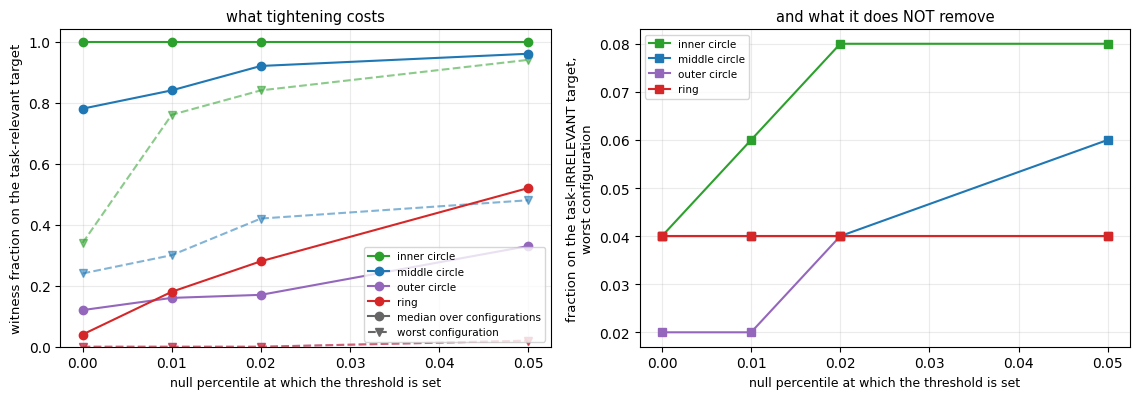

 null percentile  target  target, median  target, worst configuration  irrelevant target, median  irrelevant target, worst
            0.05 t_inner             1.0                         0.94                       0.02                      0.08
            0.02 t_inner             1.0                         0.84                       0.02                      0.08
            0.01 t_inner             1.0                         0.76                       0.02                      0.06
            0.00 t_inner             1.0                         0.34                       0.02                      0.04


In [12]:
rows = []
for fpr in (0.05, 0.02, 0.01, 0.0):
    dsw.FPR = fpr
    ct = dsw.cell_table(best, n_boot=1)
    for fam in dplt.FAMILIES:
        r = ct[(ct.family == fam) & (ct.task == "relevant")].rate
        i = ct[(ct.family == fam) & (ct.task == "irrelevant")].rate
        rows.append({"null percentile": fpr, "target": fam,
                     "target, median": r.median(), "target, worst configuration": r.min(),
                     "irrelevant target, median": i.median(),
                     "irrelevant target, worst": i.max()})
dsw.FPR = 0.01
cells = dsw.cell_table(best)          # restore the working threshold
sweep = pd.DataFrame(rows)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.1))
for fam in dplt.FAMILIES:
    b = sweep[sweep["target"] == fam].sort_values("null percentile")
    ax1.plot(b["null percentile"], b["target, median"], marker="o",
             color=dplt.FAM_COLOUR[fam], label=dplt.FAM_LABEL[fam])
    ax1.plot(b["null percentile"], b["target, worst configuration"], marker="v", ls="--",
             color=dplt.FAM_COLOUR[fam], alpha=.55)
    ax2.plot(b["null percentile"], b["irrelevant target, worst"], marker="s",
             color=dplt.FAM_COLOUR[fam], label=dplt.FAM_LABEL[fam])
ax1.plot([], [], color="0.4", marker="o", label="median over configurations")
ax1.plot([], [], color="0.4", marker="v", ls="--", label="worst configuration")
ax1.set_xlabel("null percentile at which the threshold is set", fontsize=9)
ax1.set_ylabel("witness fraction on the task-relevant target", fontsize=9.5)
ax1.set_ylim(0, 1.04); ax1.grid(alpha=.25); ax1.legend(fontsize=7.5, loc="lower right")
ax1.set_title("what tightening costs", fontsize=10.5)
ax2.set_xlabel("null percentile at which the threshold is set", fontsize=9)
ax2.set_ylabel("fraction on the task-IRRELEVANT target,\nworst configuration", fontsize=9.5)
ax2.grid(alpha=.25); ax2.legend(fontsize=7.5)
ax2.set_title("and what it does NOT remove", fontsize=10.5)
plt.tight_layout(); plt.show()

print(sweep[sweep["target"] == "t_inner"].round(3).to_string(index=False))

### What we see, and which percentile is chosen

**Tightening costs sensitivity, and the price shows in the worst configurations.** For the inner circle the median
fraction stays 1.00 at all four levels — a typical configuration loses nothing. The worst configuration, however, sags:
0.94 at the 5th percentile, 0.84 at the 2nd, 0.76 at the 1st and noticeably lower at the zeroth. That is where the
whole price lies.

**On the irrelevant task, by contrast, tightening removes almost nothing.** The worst configuration gives 0.08 at the
5th percentile and 0.06 at the 1st; the median holds at 0.02 at any level. These firings pass even the zeroth
percentile: they are not calibration noise but genuine detections — the neuron really has found a closed level curve
there. We will return to them in §2.9.

**The 1st null percentile is chosen.** A false-positive result is more expensive here, and the price is a sag of the
worst configuration from 0.94 to 0.76 with the median unchanged. The 2nd percentile would be no less defensible;
looking ahead, the verdict has a **second condition** (§2.9), and it removes what either of the two levels lets
through, so the choice changes not the verdict but the amount of work left to the second condition.

**One caveat about how to read the percentile itself.** It is a **calibration constant**, not an achieved error rate.
The firing rate of the nulls on those very same nulls equals it identically — that is how the threshold is defined. If,
however, one measures the rate on nulls that **did not take part** in setting the threshold (half of the models set the
threshold, the other half checks it), it comes out at 2.4–2.7% against the nominal 1%. So "1%" below is used as the
name of a rule, not as a statement about an error rate; when the rate itself is needed, it has to be measured
separately.

### A check of the choice: errors against the ground truth

The threshold is set — now we can compute what could not be computed before. The ground truth of §1.1 says that all 25
task-relevant configurations are indeed task-relevant, and all 15 irrelevant ones are not. So on the former the
detector **must** fire, and a failure to fire there is a **miss**; on the latter it must not fire, and a firing is a
**false alarm**.

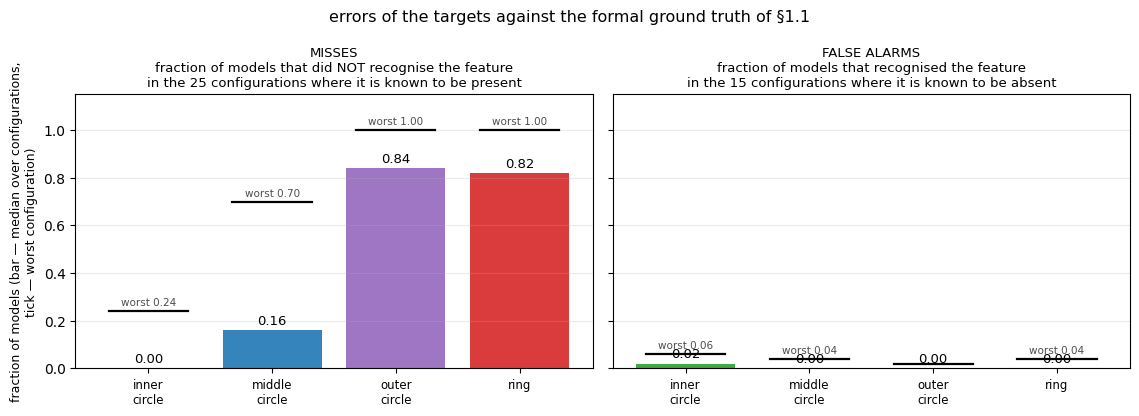

In [13]:
fams = list(dplt.FAMILIES)
miss_med = [1 - float(cells[(cells.family==f)&(cells.task=="relevant")].rate.median()) for f in fams]
miss_max = [1 - float(cells[(cells.family==f)&(cells.task=="relevant")].rate.min()) for f in fams]
fa_med   = [float(cells[(cells.family==f)&(cells.task=="irrelevant")].rate.median()) for f in fams]
fa_max   = [float(cells[(cells.family==f)&(cells.task=="irrelevant")].rate.max()) for f in fams]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
x = np.arange(len(fams))
for ax, med, mx, ttl, sub in (
        (ax1, miss_med, miss_max, "MISSES",
         "fraction of models that did NOT recognise the feature\nin the 25 configurations where it is known to be present"),
        (ax2, fa_med, fa_max, "FALSE ALARMS",
         "fraction of models that recognised the feature\nin the 15 configurations where it is known to be absent")):
    ax.bar(x, med, color=[dplt.FAM_COLOUR[f] for f in fams], alpha=.9)
    for i, (a, b) in enumerate(zip(med, mx)):
        ax.text(i, a + .025, f"{a:.2f}", ha="center", fontsize=9.5)
        ax.plot([i - .32, i + .32], [b, b], color="k", lw=1.6)
        if b - a > 0.03:
            ax.text(i, b + .022, f"worst {b:.2f}", ha="center", fontsize=7.5, color="0.3")
    ax.set_xticks(x)
    ax.set_xticklabels([dplt.FAM_LABEL[f].replace(" ", "\n") for f in fams], fontsize=8.5)
    ax.grid(alpha=.25, axis="y")
    ax.set_title(f"{ttl}\n{sub}", fontsize=9.5)
ax1.set_ylabel("fraction of models (bar — median over configurations,\n"
               "tick — worst configuration)", fontsize=9)
ax1.set_ylim(0, 1.15)
fig.suptitle("errors of the targets against the formal ground truth of §1.1", fontsize=11.5)
plt.tight_layout(); plt.show()

### What we see

**On false alarms the targets are indistinguishable** — 0.00–0.02 in median for all four, that is, at the level of the
built-in threshold and below. The choice of target could not rest on this count.

**The misses, however, diverge radically.** The inner circle misses nothing in median and loses 0.24 in the worst
configuration; the middle one misses 0.16 in median and up to 0.70 in the worst; the ring and the outer circle miss the
majority of the models on datasets where the feature is formally known to be needed by the task.

**This is an independent confirmation of the choice of §2.6.** The target was chosen by discriminating power and by the
distance to the ceiling — neither measure knows about any threshold or any ground truth. The count of errors against
the ground truth lines the targets up in the same order.

## 2.8 A by-product of the four targets: at which radius the structure is reproduced best

The target is chosen, but the four targets have also given something they were not set up for. Three of them are
concentric circles of different radius: the inner edge of the ring `1.5 − w/2`, the midline `1.5`, the outer edge
`1.5 + w/2`. Evaluating the same neurons against each of them means asking **at what distance from the centre the
network's level sets fit a circle best**. In this role a circle is called a **probing** circle: it is not "the right
target" but a probe at a given radius.

The structural criterion itself does not pose such a question: it takes the minimum over all levels and does not
constrain the radius. The three probes give a coarse localisation that a single target does not give.

**How to read the three panels.** Horizontally, everywhere, is the radius of the probe; the three points on a line are
the inner edge, the middle and the outer edge, and the two lines are the two ring widths. Vertically, one and the same
quantity in three units: the normalised target score, the absolute Chamfer distance and the ratio "floor / target".
Three units are shown because the diameters of the targets differ (2.0, 3.0, 4.0 at `w = 1.0`) and the normalisation by
itself could create or destroy an order.

**The direction of a possible bias is known in advance.** By §2.4 the normalised ceiling falls as `1/diam`, that is, the
normalisation **eases** a large target: it gives the outer circle a head start.

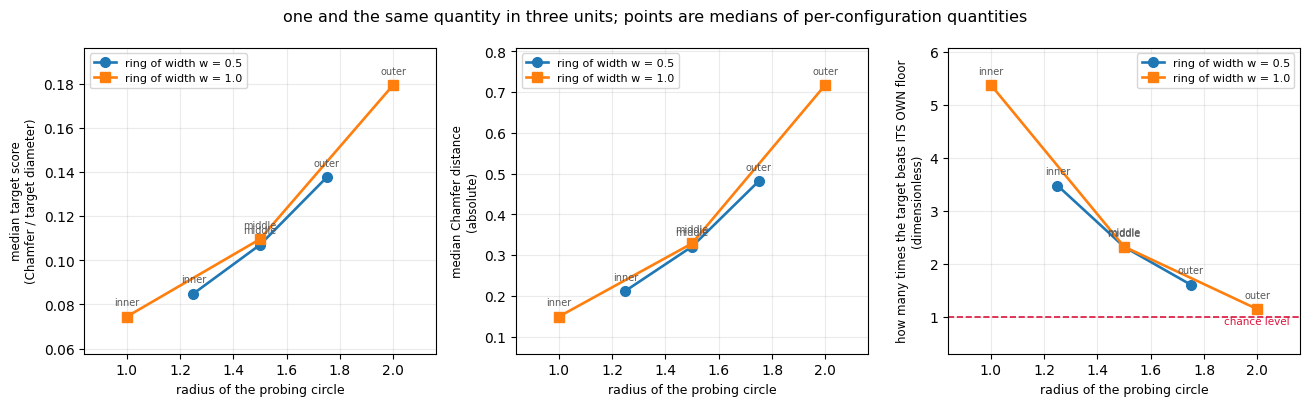

"inner better than middle, middle better than outer" — in 18 configurations of 18

              min  median    max
w   target                      
0.5 t_inner  1.73    3.48   6.67
    t_mid    1.30    2.32   4.12
    t_outer  1.06    1.60   2.29
1.0 t_inner  3.16    5.38  10.41
    t_mid    1.44    2.32   3.15
    t_outer  0.89    1.14   1.21


In [14]:
br, br_cells = dsw.bracket_table(best, cells)
fig = dplt.plot_bracket(br, title="one and the same quantity in three units; "
                                  "points are medians of per-configuration quantities")
plt.show()

piv = br_cells.pivot_table(index="cell", columns="target", values="times better than floor")
ok = int(((piv.t_inner > piv.t_mid) & (piv.t_mid > piv.t_outer)).sum())
print(f'"inner better than middle, middle better than outer" — in {ok} configurations of {len(piv)}\n')
print(br_cells.groupby(["w", "target"])["times better than floor"]
      .agg(["min", "median", "max"]).round(2).to_string())

### What we see

**The further out the probe, the worse it is reproduced.** The ratio "floor / target" decreases **as the radius of the
probing circle grows**: 3.48 → 2.32 → 1.60 at `w = 0.5` and 5.38 → 2.32 → 1.14 at `w = 1.0`. And this is not a
decrease of the block median: the inequality holds in 18 configurations of 18.

**The absolute floor hardly depends on the radius of the probe:** 0.733 / 0.745 / 0.769 at `w = 0.5` and
0.784 / 0.753 / 0.795 at `w = 1.0` — a spread of 4%. "Hitting by chance" is equally hard for a circle of any of the
three radii, so the middle panel is an honest scale.

**The absolute distance of the target, on the contrary, grows strongly:** 0.212 → 0.321 → 0.481 and 0.149 → 0.329 →
0.718. At `w = 1.0` the outer probe has practically drawn level with its floor.

**All three panels give the same order**, and the outer circle turns out the worst **despite the head start** that the
normalisation gives it.

**The effect strengthens with width.** At `w = 0.5` the probes are spaced by ±0.25 and the ratio goes 3.48 → 1.60; at
`w = 1.0` they are spaced by ±0.5 and it goes 5.38 → 1.14.

### What follows from this — and what does not

**The regularity is measured reliably:** the network's level sets fit a circle the better, the closer the circle is to
the inner edge of the ring, and the difference grows with the distance between the probes.

**But it has at least two explanations, and the data of this experiment do not choose between them.**

*The first.* A relevant topological feature is formed by the pair "feature + interior of the opposite class", the
network represents the zone of their contact, and the inner edge is exactly that zone. Then the position of the
structure is meaningful.

*The second.* A neuron simply forms a "cap" with an extremum somewhere at the centre of the disk, and the level sets of
such caps are the rounder, the closer they are to the extremum, losing their roundness with distance. Then the
observed monotonicity is a property of the shape of the field, not of the network's attention to the inner edge, and
the network "could not have done otherwise".

They can be told apart only by changing the geometry of the pair independently of the geometry of the feature, and in
this experiment the ring and the disk are concentric in all forty configurations. **This is exactly the question of
experiment 5**, and here the regularity is recorded as an observation, without a causal reading.

## 2.9 The second condition of the verdict: did the witness survive the composition

§2.7 left one thing open: the firings on the **irrelevant target** are not removed by the threshold at any percentile —
they pass even the zeroth, because the neuron really has found a closed level curve there. An instrument of a different
nature is needed, and it follows from how the network is built.

**A network is the composition of its layers.** If a feature is singled out by a neuron of layer `l`, and on some later
layer no neuron singles it out, then it did not get any further through the composition — and the head, which reads the
last layer, cannot read it there. The network did not keep such a witness, which means it did not need it. This is the
check from experiment 2, here in strict form: a witness must be found on **every** layer after `l` — not only in the
head. A witness that disappears at the fourth layer and reappears in the head does not pass the test.

**The head is scored by the same criterion.** The output layer of these networks is a single linear neuron, so the
network itself is a scalar field on the plane. What is scored is `sigmoid(logit)` — the function that the classifier
actually is; this is the analogue of taking the hidden neurons after their nonlinearity. The sigmoid is strictly
monotone, so the level sets coincide with those of the logit, and the only thing that changes is which levels the scan
visits.

**This is a necessary condition, not a sufficient one.** A feature can be linearly decodable from a layer without the
level set of any single neuron encircling it, so passing the test does not make a witness "used". A failure, however,
shows that the witness was not carried any further.

In [15]:
head = dsw.load_head_scores()          # 950 pairs, computed separately (~18 min)
thr = {(r.cell, r.family): r.threshold for r in cells.itertuples()}
h = head.copy()
h["hit"] = [s <= thr.get((c, f), np.nan)
            for s, c, f in zip(h.head_score, h.dataset_type, h.family)]
h = h.merge(df[["dataset_type", "feature_name", "feature_role", "task"]].drop_duplicates(),
            on=["dataset_type", "feature_name"], how="left")
print("the head ON ITS OWN, fraction of witnesses:")
print(h.groupby(["task", "feature_role"])["hit"].agg(["size", "sum", "mean"])
       .rename(columns={"size": "pairs", "sum": "witnesses", "mean": "fraction"}).round(3).to_string())

the head ON ITS OWN, fraction of witnesses:
                         pairs  witnesses  fraction
task       feature_role                            
irrelevant null            408          1     0.002
           target           47          0     0.000
relevant   null            395          0     0.000
           target          100        100     1.000


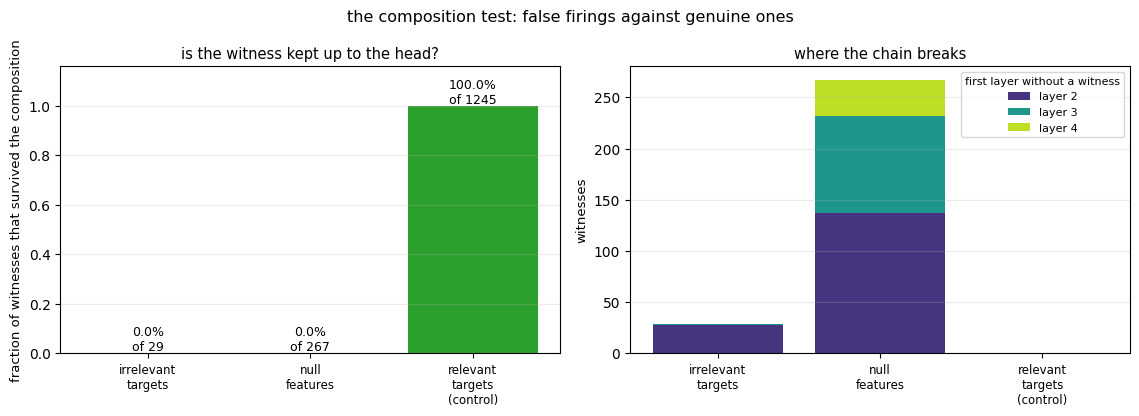

                             witnesses survived fraction
class                                                   
irrelevant targets                  29        0      0.0
null features                      267        0      0.0
relevant targets\n(control)       1245     1245      1.0

at which layer the chain breaks for the false firings:
broke at
2    165
3     96
4     35


In [16]:
cont = dsw.continuity_test(df, cells, head=head)
cont["class"] = np.where(
    cont.feature_role == "null", "null features",
    np.where(cont.task == "irrelevant", "irrelevant targets", "relevant targets"))

fp = cont[(cont["class"] != "relevant targets") & cont.decided]
CTRL = ["d4_rel_w10_R050_r100_T1000", "d4_rel_w05_R050_r100_T1000"]
ctrl = cont[(cont["class"] == "relevant targets") & (cont.family == "t_inner")
            & cont.dataset_type.isin(CTRL) & cont.decided].copy()
ctrl["class"] = "relevant targets\n(control)"

fig = dplt.plot_continuity(pd.concat([fp, ctrl]),
    title="the composition test: false firings against genuine ones")
plt.show()

print(pd.concat([fp, ctrl]).groupby("class")["survives"].agg(["size", "sum", "mean"])
      .rename(columns={"size": "witnesses", "sum": "survived", "mean": "fraction"}).round(4).to_string())
print("\nat which layer the chain breaks for the false firings:")
print(fp.groupby("broke at").size().to_string())

### What we see

**The head by itself is an almost perfect discriminator.** It witnesses the relevant target in **100 cases of 100** and
witnesses none of the 47 irrelevant targets, none of the 395 nulls on the relevant datasets, and only one of the 408
nulls on the irrelevant ones. That single case has **not a single** witness on any hidden layer — that is, it is an
isolated coincidence at the level of the output, not a lost representation.

**Not a single false firing survived the composition: 0 of 296.** Of these, 29 are on irrelevant targets and 267 on
null features. The chain breaks early — for 165 already at the second layer, for 96 at the third, for 35 at the fourth.
Not one reached the head.

**Genuine witnesses, meanwhile, pass the test completely: 1245 of 1245.** The control is taken on the inner circle in
two relevant configurations where the head has been scored for all 50 models. The contrast is complete — 0% against
100%.

**The test is robust to the choice of percentile.** At the 2nd percentile there are twice as many false witnesses (610
against 296), and of them the same **zero** survive, while the control is still at 100%. This is exactly why the choice
between the 1st and the 2nd (§2.7) does not affect the verdict.

**At a soft threshold the head starts doing work of its own.** At the 5th percentile there are 1740 false ones, 8 of
them survive (0.5%) — and **29 are filtered out by the head itself**, having reached the last hidden layer intact. That
is, computing it was no formality: at a soft threshold it is the last filter.

### Conclusion

**The firings that the threshold does not remove are removed by the composition.** The 2% of models that "find" the
feature on the irrelevant dataset find it on an intermediate layer and lose it further on: not one such neuron is
supported either by the subsequent layers or by the output of the network.

## Summary of task D

**The target for the verdict is the inner edge of the ring.** The choice is made by two measures, neither of which
requires a threshold: the discriminating power "floor / target" (4.79 against 2.32, 1.57 and 1.19 for the other three,
with the order holding in 18 configurations of 18) and the distance to the target's own ceiling (1.6× against 3.2, 4.1
and 12.9). It rests on the ground truth of §1.1: all 25 relevant configurations are formally task-relevant, so weak
discrimination on them is an error of the target, not a property of the task. The threshold, set later, lines the
targets up in the same order, which confirms the choice independently. At `w = 0` the ring degenerates into a circle,
and its inner edge is the circle itself — so the target is defined in all forty cells.

**The middle circle is needed for exactly one thing — to be a stationary probe on the width axis.** The radius of the
inner edge moves together with `w` (1.5 → 1.25 → 1.0), so along this axis the two targets ask different things: the
stationary one about density at a fixed place, the moving one about whether the structure follows the edge of the
feature. On the moving target the dimensionless "floor / target" is read next to the normalised score: the diameter
cancels in it, and the normalisation itself tightens the requirement along this axis rather than relaxing it.

**The verdict consists of two conditions, and neither is enough on its own.**

*The first: the score is below the threshold from the target's own nulls in its own configuration.* The threshold is
the **1st null percentile**, set on the whole floor of that configuration. Tightening from the 5th percentile to the 1st
costs 0.94 → 0.76 in the worst configuration with the median unchanged at 1.00, and on the irrelevant side it removes
almost nothing (0.08 → 0.06): what fires there cannot be removed by a threshold in principle.

*The second: the witness is preserved on every subsequent layer, including the head.* The first condition separates
signal from chance, the second separates a used representation from an incidental one. On these data the first lets
through 296 false firings, the second lets through none, and the genuine ones pass both in full.

**Measured as a by-product: where the structure sits.** Three concentric probes — the inner edge, the middle, the outer
edge — evaluate the same neurons, and the ratio "floor / target" decreases with the radius of the probe:
3.48 → 2.32 → 1.60 at `w = 0.5` and 5.38 → 2.32 → 1.14 at `w = 1.0`, in 18 configurations of 18. The absolute floor
hardly depends on the radius of the probe (a spread of 4%), so the scale is honest, and the normalisation gives a head
start precisely to the outer probe — which is still the worst. The network's level sets fit a circle the better, the
closer it is to the inner edge of the ring. **This receives no causal reading:** there are two explanations — the zone
of contact between the feature and the interior of the opposite class, or simply the loss of roundness of a "cap" with
distance from its extremum — and the geometry here (the ring and the disk are concentric in all forty cells) does not
choose between them. That is the question of experiment 5.

**Also measured as a by-product: the task is visible at the output of the network.** The head — a single linear
neuron, so that the network itself is a scalar field on the plane — witnesses the relevant target in 100 cases of 100
and is silent on all 47 irrelevant targets, on all 395 nulls of the relevant datasets and on 407 of the 408 nulls of
the irrelevant ones. This is not part of the verdict (the head is not a hidden-layer neuron), but it is the shortest
check that the difference between the two tasks has to do with what the network computes, and not only with how its
intermediate representations are arranged.

**What carries over.**

* **A target is a sample of a region of space, and its spacing is a parameter of the instrument.** The condition
  `δ(A) < h` (the target's spacing finer than the grid step) holds for the three circles — `δ/h` = 0.19 / 0.28 / 0.37,
  and their measured ceilings are 0.0337 / 0.0342 / 0.0360 against `h/2 = 0.0339` — and **is violated for the ring**
  (`δ/h = 1.43`: the same points cover an area, not a curve). Hence the ring's ceiling is 45% higher; this is one more
  reason not to take it as the target, and the first of those visible before any computation.
* **Targets of different size are comparable only by dimensionless ratios** — "floor / target" and "achieved /
  ceiling" — because the normalised score divides by the target's diameter a discrepancy whose size is set by the grid
  step and does not depend on the target.
* **The floor is measured in its own configuration** and never pooled across configurations.
* **Formal task-relevance can and should be checked with chromatic TDA** before any training.


---

# 3. Task A — can density alone manufacture a witness?

**Question.** Experiment 1 did not find a single witness of the task-irrelevant circle. Here we try to **manufacture**
one without touching relevance: give the feature more points, lay them more densely, enlarge the sample as a whole.

**Why it is needed.** This is the decisive task of the experiment. The density hypothesis claims that level sets stick
to concentrations of points by themselves; if so, then on a dataset where the task does not see the feature it is
enough to make the feature dense — and a witness will appear. If it does not appear at any density, the hypothesis is
rejected in the most direct form possible.

**How we check.** `simple_irrelevant`: the ring at the origin (class 0), the disk at `(−6, 0)` (class 1). The task is
linearly separable, the feature is not needed to solve it. Inside the ring there is **no object of the opposite
class** — the disk has been carried far away. Two axes — the width `w ∈ {0, 0.5, 1.0}` and the balance
`ρ ∈ {0.25, 1, 4}` at `T = 1000`. **9 cells.** Both axes are the same as in task B, and this makes the two tasks
comparable: they differ only in relevance.

**One caveat about the target, and it matters precisely here.** The inner edge was chosen in §2.6 partly on a
substantive motive: a relevant topological feature is formed by the pair "feature + interior of the opposite class",
and the inner edge is closest to the zone of their contact. On the irrelevant dataset this motive is absent
altogether — the inside of the ring is empty, and the only object of the other class lies outside and far away, so
"closer to it" would be precisely the outer edge. So here we do **not** pretend that the target was chosen on that
motive: below it is shown that **all four targets give the same answer**, and the choice influences nothing. The inner
edge is used simply for comparability with task B.

**What the result will say.** No witnesses anywhere — the hypothesis is rejected. They appear as density grows — it is
confirmed, and the conclusions of experiments 1 and 2 have to be reread. No witnesses, but the score improves
systematically — there is an effect, but it falls short of the threshold, and one has to report the magnitude rather
than the verdict.

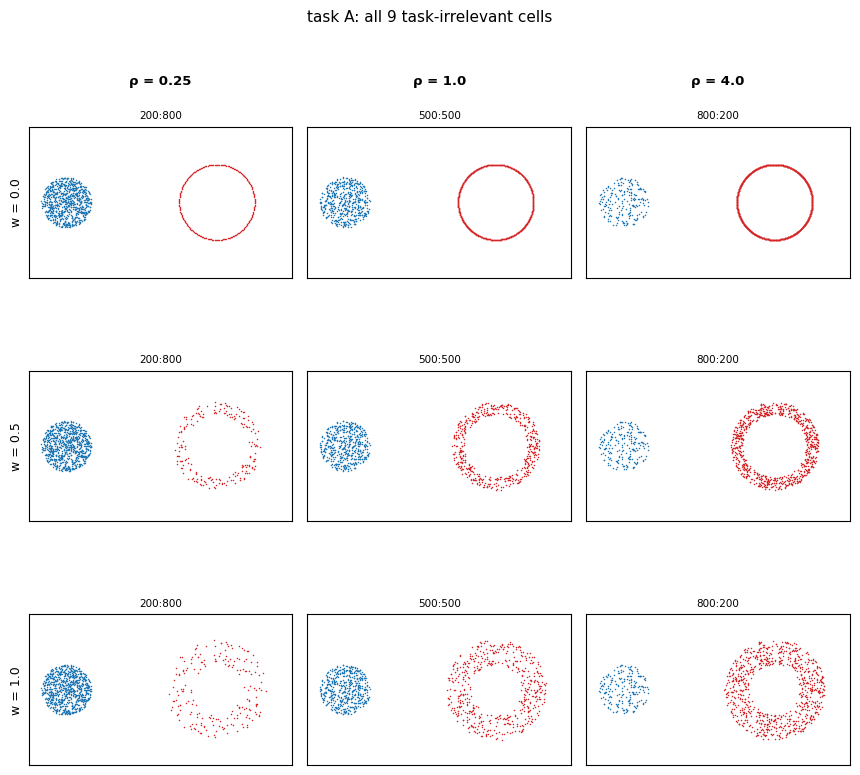

In [17]:
fig = dplt.plot_dataset_grid(IRR, dsw.dataset_points, ncols=3, size=2.6,
    xlim=(-7.5, 3.0), ylim=(-3.0, 3.0), label_of=label,
    row_labels=[f"w = {w}" for w in W3],
    col_labels=[f"ρ = {r}" for r in RHO3],
    title="task A: all 9 task-irrelevant cells")
plt.show()

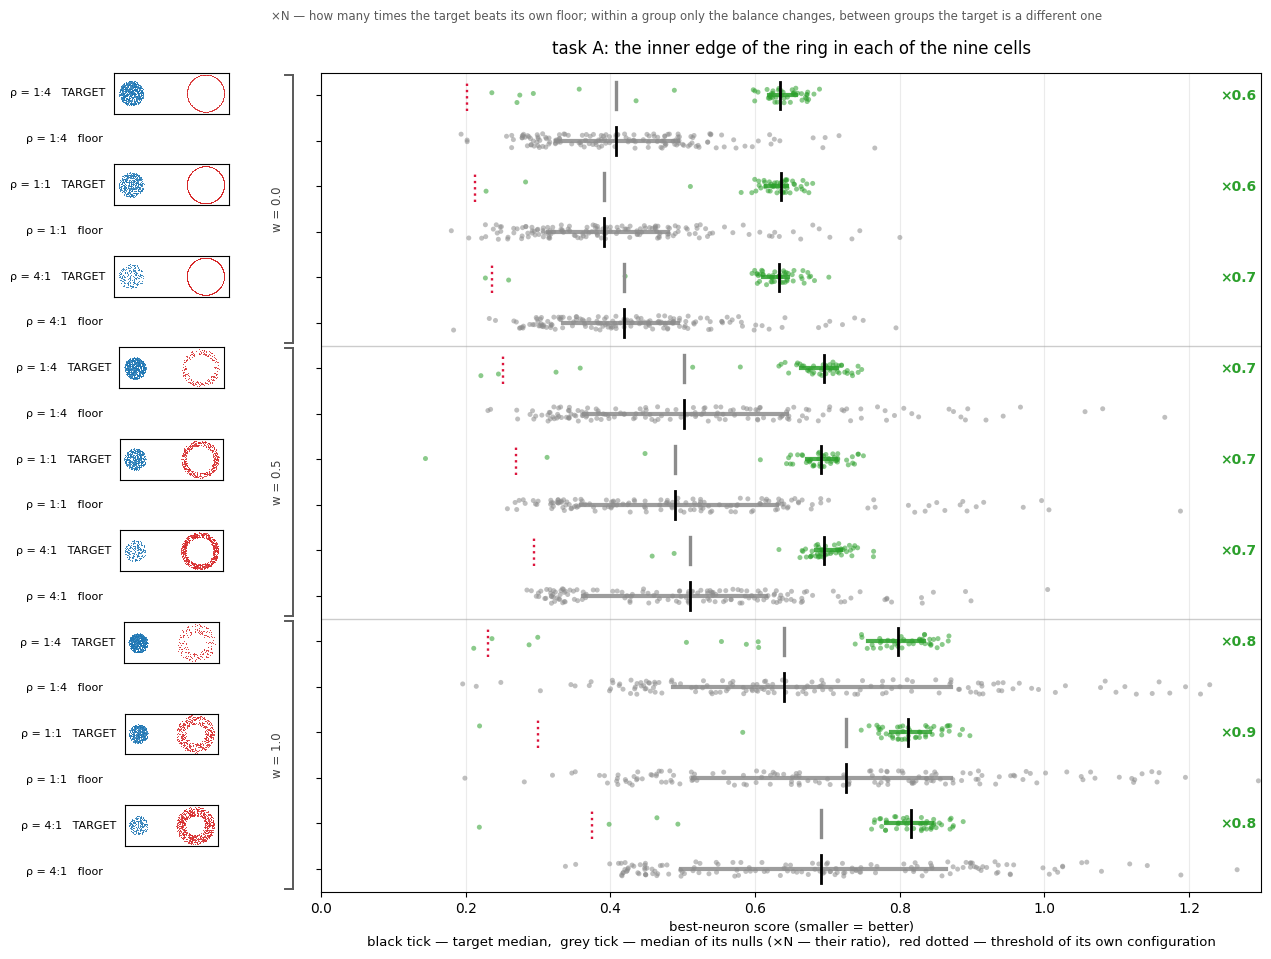

In [18]:
# Nine cells as populations: the target against its own floor, cell by cell.
# The target is the inner edge (§2.6), and each cell has its own threshold (§2.7).
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for w in W3:
    for rho in RHO3:
        n, fam = C(task="irrelevant", w=w, rho=rho, T=1000)[0], FAM(w)
        s = best[(best.dataset_type == n) & (best.family == fam)]
        r = cells[(cells.cell == n) & (cells.family == fam)].iloc[0]
        rows.append((f"ρ = {ratio_label(rho)}   TARGET", s[s.feature_role == "target"].score, dplt.CT))
        thumbs.append(n); thr.append(float(r.threshold))
        rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
        rows.append((f"ρ = {ratio_label(rho)}   floor", s[s.feature_role == "null"].score, dplt.CN))
        thumbs.append(None); thr.append(None); rat.append(None); nul.append(None)
    groups.append((f"w = {w}", 6))

fig = dplt.plot_strips(rows, xlim=(0, 1.3), height=0.42, row_thresholds=thr,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="task A: the inner edge of the ring in each of the nine cells",
    caption="×N — how many times the target beats its own floor; within a group only the balance changes, "
            "between groups the target is a different one")
plt.show()

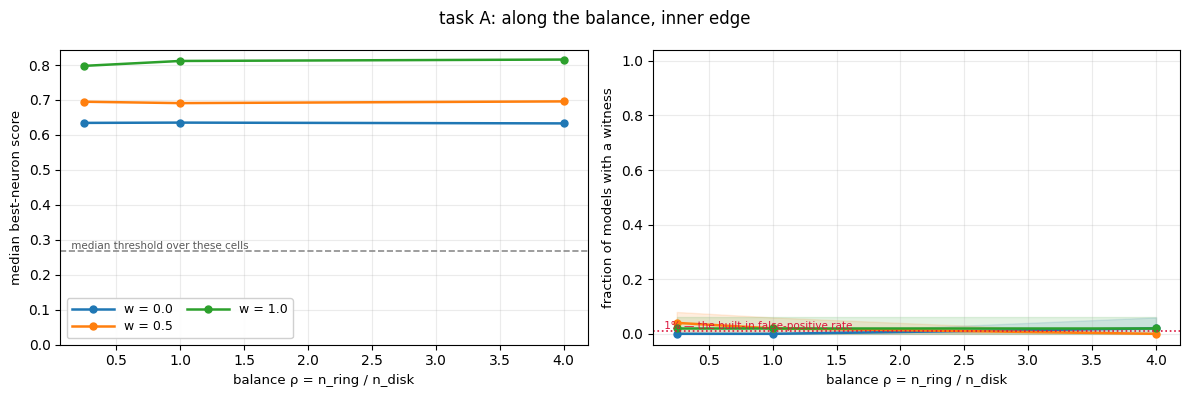

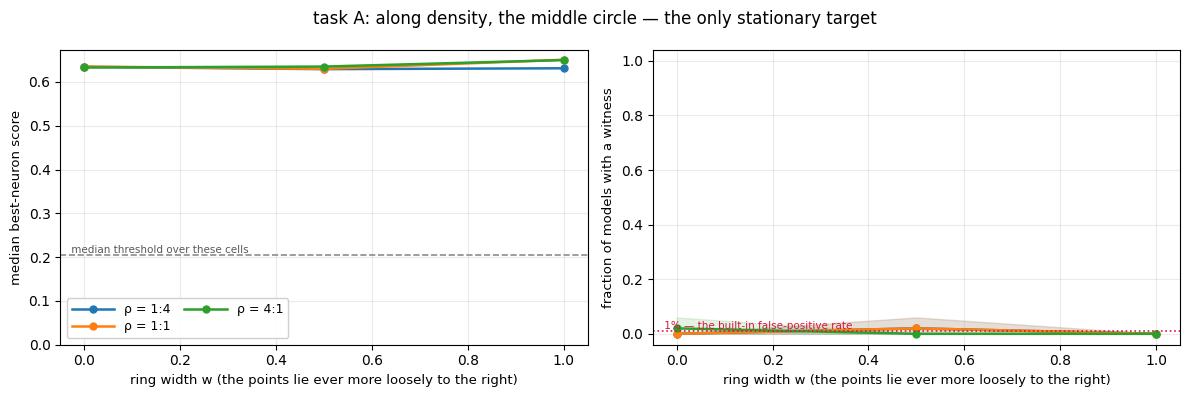

In [19]:
# The balance axis — on the verdict target: within a panel the width is fixed, so the target is one and the same.
fig = dplt.plot_axis_panels(cells, "rho", family="edge", task="irrelevant",
    panels=[{"label": f"w = {w}", "sel": {"w": w, "T": 1000},
             "colour": c} for w, c in zip(W3, ("#1f77b4", "#ff7f0e", "#2ca02c"))],
    xlabel="balance ρ = n_ring / n_disk", suptitle="task A: along the balance, inner edge")
plt.show()

# The width axis — on the MIDDLE circle: its radius is 1.5 at any width, whereas
# the inner edge moves 1.5 → 1.25 → 1.0 and would mix density with the move (§2.6).
fig = dplt.plot_axis_panels(cells, "w", family="t_mid", task="irrelevant",
    panels=[{"label": f"ρ = {ratio_label(r)}", "sel": {"rho": r, "T": 1000},
             "colour": c} for r, c in zip(RHO3, ("#1f77b4", "#ff7f0e", "#2ca02c"))],
    xlabel="ring width w (the points lie ever more loosely to the right)",
    suptitle="task A: along density, the middle circle — the only stationary target")
plt.show()

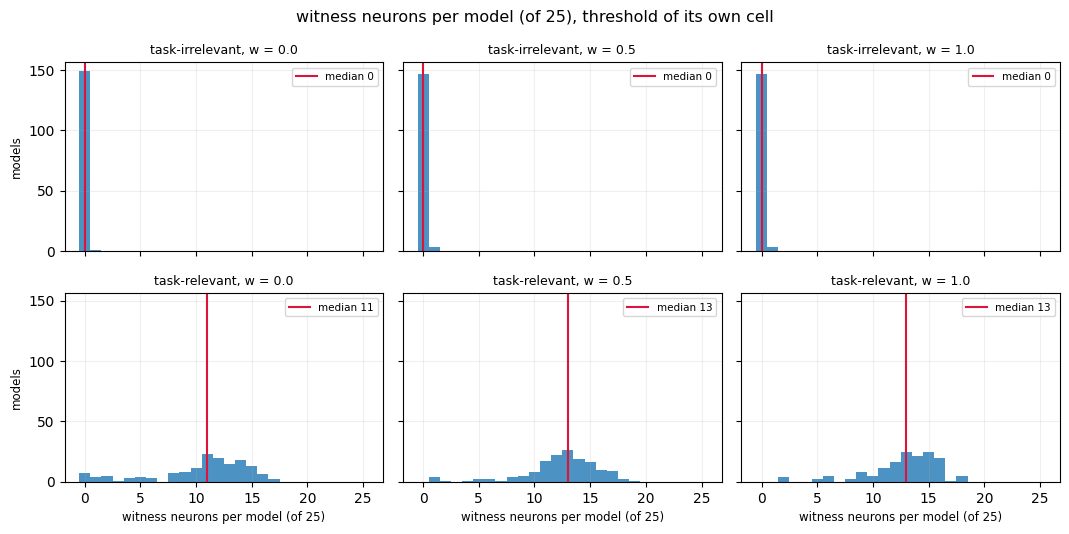

In [20]:
# How many of a model's neurons pass the threshold at all — not "is there at least one" but how many.
# Each cell has its own threshold; the target is the inner edge.
groups_m = {}
for task, names in (("task-irrelevant", IRR),
                    ("task-relevant", [n for n in REL if dsw.cell_of(n)["R"] == 0.5])):
    for w in W3:
        sel = [n for n in names if dsw.cell_of(n)["w"] == w]
        groups_m[f"{task}, w = {w}"] = dsw.multiplicity(df, sel, family=None, threshold=cells)
fig = dplt.plot_multiplicity(groups_m, title="witness neurons per model (of 25), "
                                             "threshold of its own cell")
plt.show()

In [21]:
# Does the answer of task A depend on the choice of target? We compute all four over all irrelevant cells.
A4 = cells[cells.task == "irrelevant"]
tab = A4.groupby("family").apply(lambda g: pd.Series({
    "cells": g.cell.nunique(),
    "fraction, median": g.rate.median(), "fraction, max": g.rate.max(),
    "p_superior, median": g.p_superior.median(),
    "target worse than its floor": f"{int((g.med_target > g.med_null).sum())} of {len(g)}",
}), include_groups=False)
print("task A on EACH of the four targets:")
print(tab.loc[list(dplt.FAMILIES)].to_string())
print("\nthe answer is the same on all four: the verdict does not depend on the choice of target")

task A on EACH of the four targets:
         cells  fraction, median  fraction, max  p_superior, median target worse than its floor
family                                                                                         
t_inner     12              0.02           0.06            0.248867                    12 of 12
t_mid       15              0.00           0.04            0.097733                    15 of 15
t_outer     12              0.00           0.02            0.052467                    12 of 12
t_ring      12              0.00           0.04            0.059200                    12 of 12

the answer is the same on all four: the verdict does not depend on the choice of target


### What we see

**The green rows do not shift along either axis.** Along the balance the range of the median is 0.002 / 0.005 / 0.018
over the three widths — neither tripling the number of points on the ring nor starving it moves the target noticeably
against the size of the quantity itself, 0.63–0.82. Along the width (the middle circle, the right-hand pair of panels)
the median stands at 0.63–0.65. Both panels are flat.

**The witness fraction is at the level of the threshold.** It runs 0.00–0.04 over the nine cells with a median of 0.02,
while the threshold by construction lets through 1% of the nulls: these are errors of the threshold, not a signal.

**And the choice of target does not influence anything here.** The table over all four targets: a median fraction of
0.00–0.02 with a maximum of 0.06, a median `p_superior` of 0.05–0.25, and the target is worse than its own floor **in
all** cells for **each** of the four. The caveat from the introduction is removed by measurement: on the irrelevant
dataset the inner edge is not privileged and need not be — they all answer the same.

**The target is systematically WORSE than its own floor.** The green rows lie to the right of the grey ones in all nine
cells; the median `p_superior` = 0.18 — and the same 0.18 with an interval of [0.14, 0.27] if computed over all fifteen
irrelevant cells, including the `T = 5000` slice. This is not "no effect" — it is an effect of the opposite sign: the
circle at the origin is reproduced worse than its copy in an empty place. It looks as if, in the region where the
network actually computes something, the level sets are more varied and fit a circle worse than in the void, where the
field is almost linear.

**The multiplicity histograms settle the question.** In the irrelevant cells the threshold of its own cell is passed by
zero neurons in 98–99% of the models, and the distribution does not change with width. In the relevant ones the same
picture is arranged quite differently — there the median is 11–13 neurons of 25.

### Conclusions

**The density hypothesis is rejected, and rejected more strongly than was required.** What was required was to show
that density does not manufacture a witness; what came out is that the feature is represented there not "not at all"
but worse than chance.

**This is not blindness of the instrument.** The same 50 models under the same criterion give a witness in almost every
relevant cell (§4), and the difference is visible on the same plots. The zero here is a property of the dataset.

**The conclusion of experiment 1 about relevance has held**, and everything that follows can be read as "what modulates
an already existing effect", not "whether it exists".

---

# 4. Task B — what determines the quality of the witness where the feature is needed

**Question.** Since density does not create a witness out of nothing, the next question is what, within the relevant
task, determines how good the witness is.

**Why it is needed.** Task A removed density as a **cause** of the appearance of the representation. But it could have
remained its **modulator** — and then every comparison between experiments with a different density of the sample would
have to be corrected for it. Here we also test the thesis that a relevant topological feature is formed in equal
measure by the feature itself and by its interior of the opposite class: if so, the disk axis should give an effect
comparable to that of the ring axis.

**How we check.** `simple_relevant`: a ring of class 0 around a disk of class 1, the task forces a closed boundary
between them. Three axes — the width `w`, the disk radius `R`, the balance `ρ` — at `T = 1000`. **18 cells**, analysed
one axis at a time.

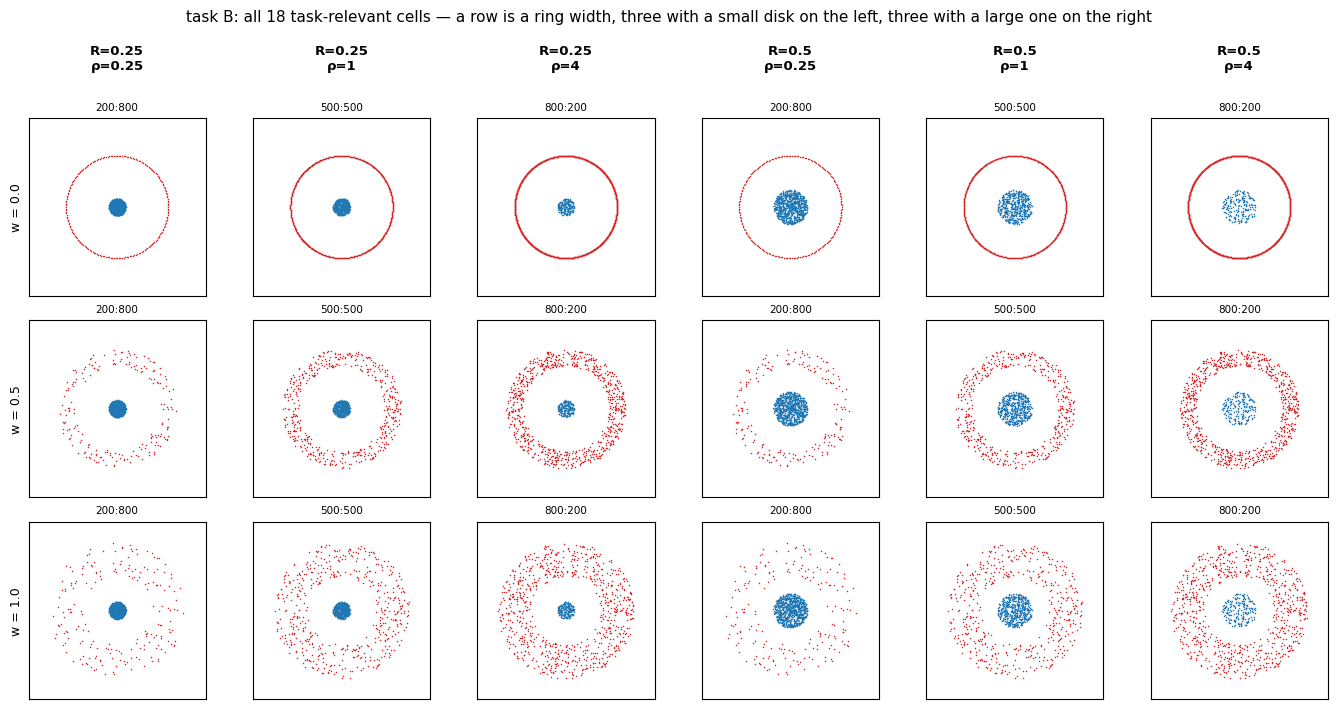

In [22]:
fig = dplt.plot_dataset_grid(REL, dsw.dataset_points, ncols=6, size=2.15,
    xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), label_of=label,
    row_labels=[f"w = {w}" for w in W3],
    col_labels=["R=0.25\nρ=0.25", "R=0.25\nρ=1", "R=0.25\nρ=4",
                "R=0.5\nρ=0.25", "R=0.5\nρ=1", "R=0.5\nρ=4"],
    title="task B: all 18 task-relevant cells — a row is a ring width, "
          "three with a small disk on the left, three with a large one on the right")
plt.show()

## 4.1 The width axis: what actually changes along it

This axis was conceived as a pure density axis: the point counts of the ring and the disk, the disk radius and the box
are fixed along it, while the transition `w = 0.5 → 1.0` increases the distance to the nearest neighbour 1.4 times,
and the transition from `w = 0` threefold.

**But density is not the only thing that changes along it, and this has to be named plainly.** The ring widens inwards
and outwards at once, so its inner edge moves towards the centre: 1.5 → 1.25 → 1.0. Together with it, the **gap**
between the feature and the interior narrows — `1.5 − w/2 − R`, that is, 1.25 → 1.00 → 0.75 at `R = 0.25` and
1.00 → 0.75 → 0.50 at `R = 0.5`. Density falls and the gap narrows along one and the same axis.

So the axis is read with two targets, and they answer **different** questions.

**The stationary probe is the middle circle of radius 1.5.** It stays in place at any width, so the question on it is
clean: does the picture at a FIXED place deteriorate because the points lie sparser?

**The verdict target is the inner edge.** It moves together with the feature, and the question on it is a different
one: does the network's structure follow the edge of the feature?

Both targets are read in the usual units — **the score divided by `diam(A)`**, as everywhere in this project. But the
diameter of the inner edge changes along the axis (3.0 → 2.5 → 2.0), so next to the score each row carries **`×N` —
how many times the target's median is better than the median of its own nulls**. This ratio is dimensionless, the
diameter cancels in it, and it is comparable along the whole axis without caveats (§2.4). Which way the normalisation
pulls the score is known in advance: the ceiling of the instrument equals `h/2 / diam(A)` and **grows** as the target
shrinks — 0.0113 → 0.0136 → 0.0170 — that is, the normalisation plays **against** an improvement, not for it.

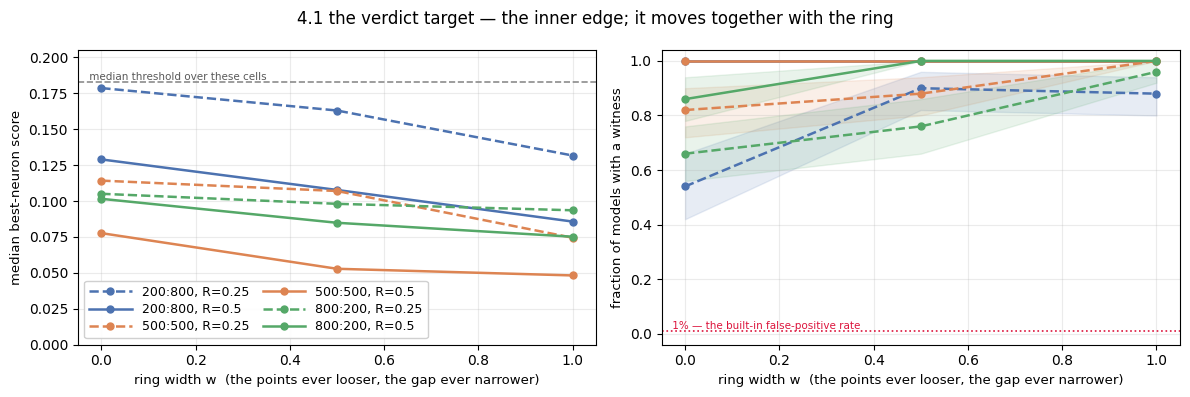

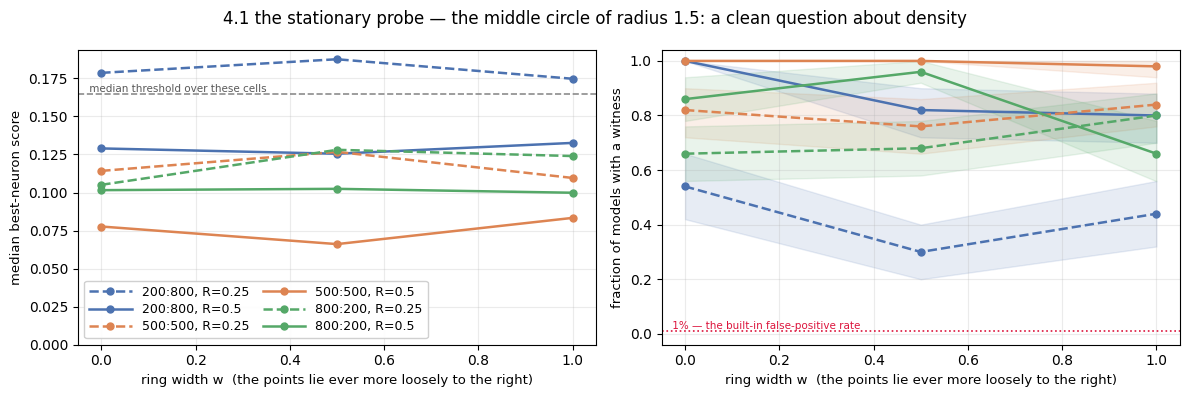

In [23]:
COL = {0.25: "#4c72b0", 1.0: "#dd8452", 4.0: "#55a868"}
panels_w = [{"label": f"{dsw.n_ring_of(r,1000)}:{1000-dsw.n_ring_of(r,1000)}, R={R}",
             "sel": {"rho": r, "R": R, "T": 1000}, "colour": COL[r],
             "ls": "-" if R == 0.5 else "--"}
            for r in RHO3 for R in (0.25, 0.5)]

cw = cells.copy()
cw["gap"]          = 1.5 - cw.w / 2 - cw.R
cw["floor/target"] = cw.med_null / cw.med_target
cw["diameter"]     = [2 * dsw.target_radius(f, w) for f, w in zip(cw.family, cw.w)]
cw["abs_target"]   = cw.med_target * cw["diameter"]

fig = dplt.plot_axis_panels(cells, "w", panels_w, family="edge",
    xlabel="ring width w  (the points ever looser, the gap ever narrower)",
    suptitle="4.1 the verdict target — the inner edge; it moves together with the ring")
plt.show()

fig = dplt.plot_axis_panels(cells, "w", panels_w, family="t_mid",
    xlabel="ring width w  (the points lie ever more loosely to the right)",
    suptitle="4.1 the stationary probe — the middle circle of radius 1.5: a clean question about density")
plt.show()

In [24]:
# The witness fraction on the stationary probe jitters with the threshold, not with density: the 1st percentile
# of a hundred nulls is almost the minimum and is noisy (§2.7). The check is a common threshold for the whole row.
Bm = cells[(cells.task == "relevant") & (cells.family == "t_mid")
           & (cells.R < 1.0) & (cells["T"] == 1000)]
own, common = [], []
for _, g in Bm.groupby(["rho", "R"]):
    g = g.sort_values("w")
    bar = float(g.threshold.median())
    fixed = [float((best[(best.dataset_type == r.cell) & (best.family == "t_mid")
                         & (best.feature_role == "target")].score <= bar).mean())
             for r in g.itertuples()]
    own.append(g.rate.max() - g.rate.min()); common.append(max(fixed) - min(fixed))
print(f"stationary probe: range of the fraction within a row {min(own):.2f}-{max(own):.2f} with its own threshold "
      f"and {min(common):.2f}-{max(common):.2f} with a common threshold for the row")

stationary probe: range of the fraction within a row 0.02-0.30 with its own threshold and 0.02-0.14 with a common threshold for the row


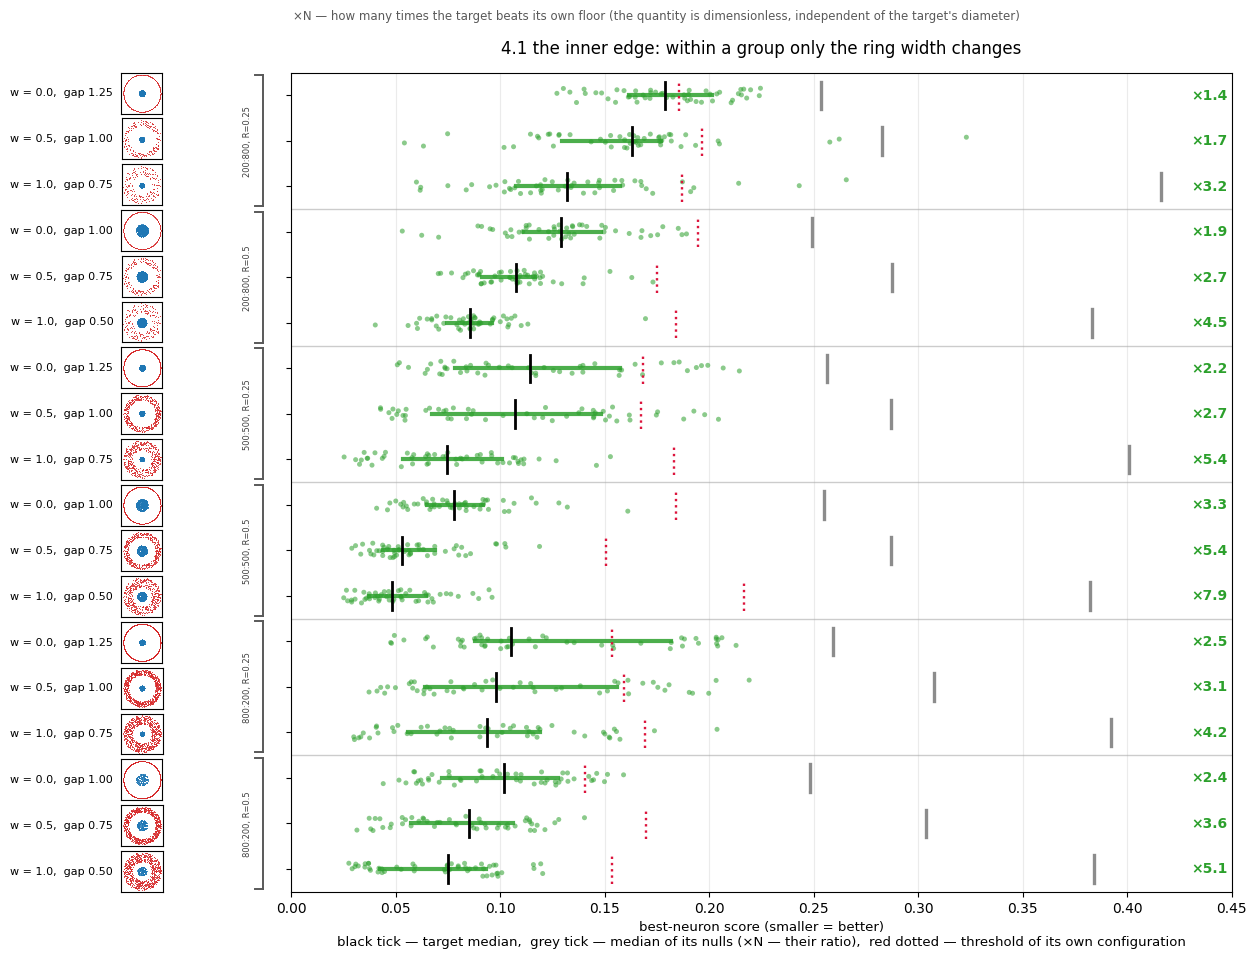

In [25]:
# All eighteen relevant cells; within a group only the ring width changes,
# and with it the gap between the feature and the interior.
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for rho in RHO3:
    for R in (0.25, 0.5):
        for w in W3:
            n, fam = C(task="relevant", w=w, R=R, rho=rho, T=1000)[0], FAM(w)
            b = best[(best.dataset_type == n) & (best.family == fam)]
            r = cells[(cells.cell == n) & (cells.family == fam)].iloc[0]
            rows.append((f"w = {w},  gap {1.5 - w/2 - R:.2f}",
                         b[b.feature_role == "target"].score, dplt.CT))
            thumbs.append(n); thr.append(float(r.threshold))
            rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
        nr = dsw.n_ring_of(rho, 1000)
        groups.append((f"{nr}:{1000-nr}, R={R}", 3))
fig = dplt.plot_strips(rows, xlim=(0, 0.45), row_thresholds=thr, height=0.42,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="4.1 the inner edge: within a group only the ring width changes",
    caption="×N — how many times the target beats its own floor (the quantity is dimensionless, "
            "independent of the target's diameter)")
plt.show()

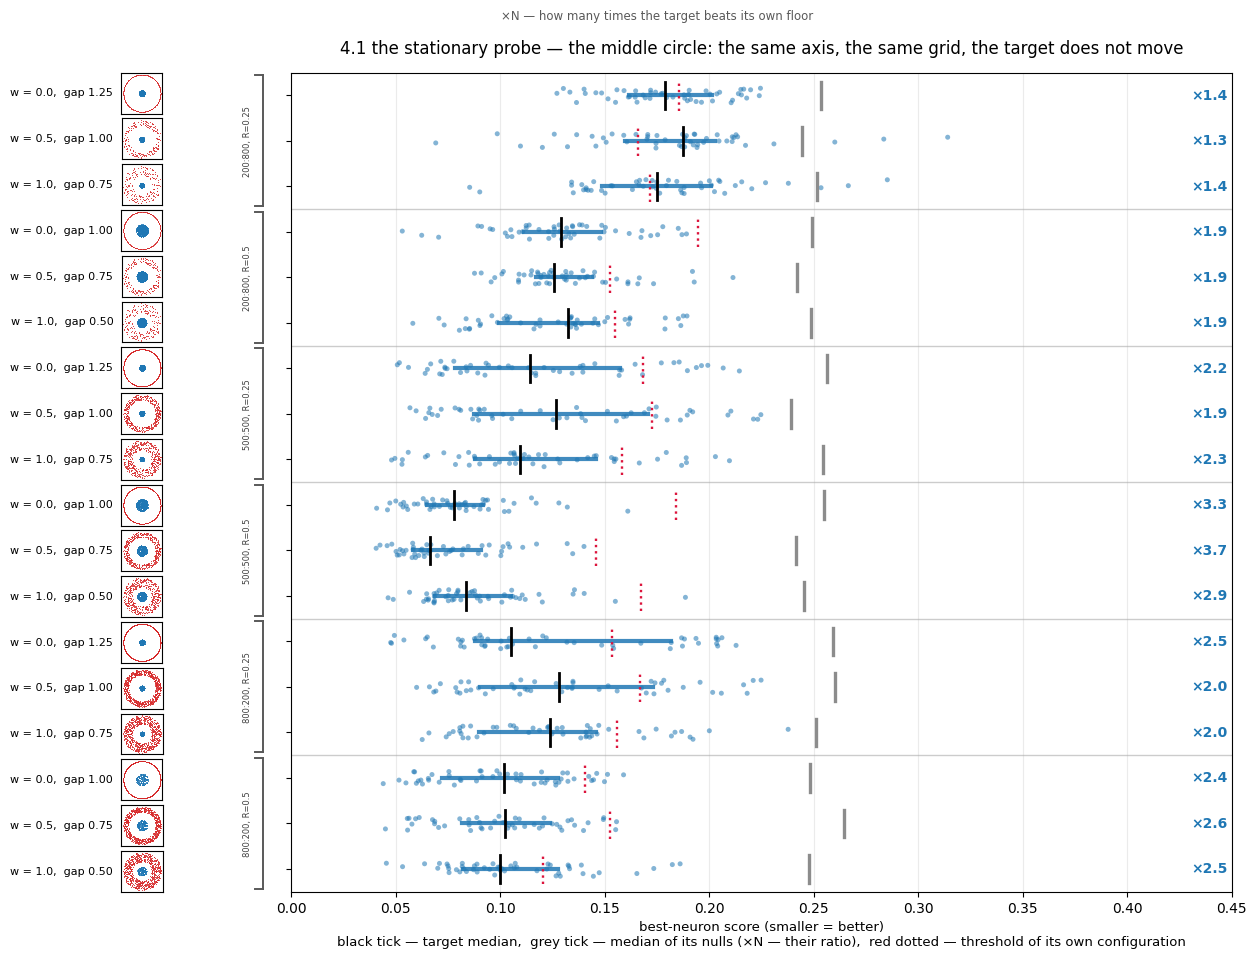

In [26]:
# The same grid and the same axis, but the target is STATIONARY: the middle circle of radius 1.5.
# Compare with the previous picture row by row — the first row of each group
# is the same in both, because at w = 0 the inner edge is this very circle.
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for rho in RHO3:
    for R in (0.25, 0.5):
        for w in W3:
            n = C(task="relevant", w=w, R=R, rho=rho, T=1000)[0]
            b = best[(best.dataset_type == n) & (best.family == "t_mid")]
            r = cells[(cells.cell == n) & (cells.family == "t_mid")].iloc[0]
            rows.append((f"w = {w},  gap {1.5 - w/2 - R:.2f}",
                         b[b.feature_role == "target"].score, dplt.FAM_COLOUR["t_mid"]))
            thumbs.append(n); thr.append(float(r.threshold))
            rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
        nr = dsw.n_ring_of(rho, 1000)
        groups.append((f"{nr}:{1000-nr}, R={R}", 3))
fig = dplt.plot_strips(rows, xlim=(0, 0.45), row_thresholds=thr, height=0.42,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="4.1 the stationary probe — the middle circle: the same axis, the same grid, the target does not move",
    caption="×N — how many times the target beats its own floor")
plt.show()

### What we see

**On the stationary probe nothing happens.** All six lines of the middle circle are horizontal: the range of the median
within a line is 0.003–0.023 against 0.121 between the lines. The strip plot shows this row by row — within each group
the rows lie on top of each other in both medians and tails, and `×N` stays in place: 1.4 → 1.3 → 1.4,
1.9 → 1.9 → 1.9, 3.3 → 3.7 → 2.9, a range within a group of 0.06–0.71 and with no consistent sign. The ring's points
lie three times looser — and at the fixed radius 1.5 this changes neither the median nor the shape of the
distribution. This is the answer about density: **by itself it spoils nothing**. The witness fraction on this probe
jitters more (up to 0.30 within a line), but it jitters with the threshold: the 1st percentile of a hundred nulls is
almost the minimum and is noisy (§2.7), and with a common threshold for the row the range halves.

**One group drops out downwards, and it is also the worst on the whole grid.** In the group `200:800, R = 0.25` — a
starved ring with a small disk — the witness fraction goes 0.54 / 0.30 / 0.44, that is, in two rows of three fewer than
half of the models pass the verdict: the target's median there turns out to be **to the right of the threshold**
(0.188 against 0.166 and 0.175 against 0.172). This is not a counting glitch: in the same rows the target is 1.3–1.4
times better than the median of its nulls (0.24) — it is just that the threshold is taken at the 1st percentile of the
nulls, not at their median, and the bar stands much further to the left. On the verdict target the same group gives
0.54 / 0.90 / 0.88. The worst corner of the grid is a starved feature together with a small interior, and §4.2 and
§4.3 analyse both of these coordinates separately.

**On the verdict target, by contrast, everything improves — in the usual normalised score too.** The median goes
0.1786 → 0.1630 → 0.1317 in the worst row and 0.0777 → 0.0529 → 0.0482 in the best; an improvement **in six rows of
six**, and this is already after dividing by `diam(A)`. The ratio "floor / target", which does not depend on the
diameter at all, grows from 1.4–3.3 at `w = 0` to 3.2–7.9 at `w = 1.0`.

**The two strip plots are worth comparing row by row.** The grid, the models, the criterion and the threshold are the
same in both — only the target differs. **The first row of each group is the same in both pictures**: at `w = 0` there
is no ring, and the inner edge coincides with the middle circle, so both begin with 1.4 / 1.9 / 2.2 / 3.3 / 2.5 / 2.4.
After that one picture drifts to the left, and `×N` in it grows monotonically in six groups of six (to 3.2, 4.5, 5.4,
7.9, 4.2, 5.1), while the other stays in place. They part exactly where the target starts moving together with the
feature. The witness fraction, by the end of the axis, falls nowhere (0.54 → 0.88, 0.66 → 0.96, 0.82 → 1.00), and in
two rows it is 1.00 from the very start.

**The normalisation works AGAINST the observed improvement, not for it.** The target shrinks along the way, while the
normalised ceiling of the instrument equals `h/2 / diam(A)` and therefore grows: 0.0113 → 0.0136 → 0.0170. That is, the
attainable limit along the axis **worsens** by exactly a factor of one and a half, while the measured score improves
1.1–1.6 times. In the ratio "achieved / ceiling" — the only one in which both corrections are already taken into
account — this is an improvement by a factor of **1.7–2.4**, and the independent ratio "floor / target" grows by
exactly as much. What is observed in the normalised score is a lower estimate of the real improvement.

**This is visible on the irrelevant dataset as well, where there is nothing to follow.** There the same target moves
over the same radii, and the normalised score behaves exactly as the arithmetic of a shrinking target dictates: it
**worsens**, 0.635 → 0.695 → 0.798, and the ratio "floor / target" stays below one (0.64 → 0.85) — the target is worse
than chance at any width. One and the same geometric move of the target gives a deterioration there and an improvement
here; the difference is whether there is anything to follow.

**Density cannot explain this either — the sign is wrong.** The density hypothesis predicts that a sparser feature gives
a worse witness. Here the feature becomes three times sparser, and the witness twice as good.

**So what changes? The gap.** Together with the inner edge, the boundary between the classes moves towards the centre:
the gap `1.5 − w/2 − R` narrows 1.25 → 1.00 → 0.75 and 1.00 → 0.75 → 0.50 (it is labelled on each row of the strip
plot). The narrower it is, the more tightly the contact zone is pressed against the inner edge — that is, against the
target.

### Conclusion

**The density of the feature does not modulate the quality of the witness.** On the stationary probe it does nothing;
and where the score does move, it moves in the direction **opposite** to the prediction of the density hypothesis, and
is explained by geometry — by the narrowing of the gap, not by how tightly the points are packed.

**The width axis turned out to be not a density axis but the first gap axis.** The second is given by §4.3, where the
gap narrows from the other side — by the growth of the disk. Both have the same sign, and together they add up to a
mechanism that is formulated at the end of §4.3.

## 4.2 The balance axis: `ρ` — how the points are divided between the two objects

The balance `ρ = n_ring / n_disk` moves points between the objects **without touching the geometry**: `ρ = 0.25` gives
200 points to the ring and 800 to the disk, `ρ = 4` the other way round, `ρ = 1` divides them equally. The total number
of points stays constant, so the axis answers precisely the question "which of the two objects needs the points more".

Here there are six lines — one for each combination `(w, R)` — and within a line only the balance changes. The target
is again the verdict one, the inner edge: the width within a line is constant, so the target within a line is one and
the same, and the normalised score is directly comparable.

Next to the score the **dimensionless ratio "floor / target"** is shown (the `×N` numbers to the right of each row). It
is needed because together with the balance the field in the cell changes, and with it the floor: the score could move
not because the target is reproduced better but because things got harder for a random component. The ratio is free of
this.

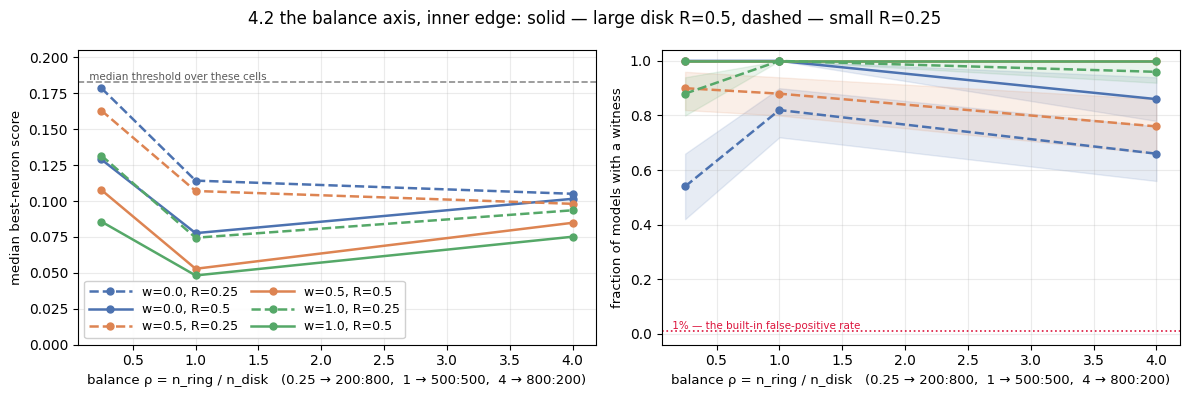

In [27]:
panels_rho = [{"label": f"w={w}, R={R}", "sel": {"w": w, "R": R, "T": 1000},
               "colour": {0.0: "#4c72b0", 0.5: "#dd8452", 1.0: "#55a868"}[w],
               "ls": "-" if R == 0.5 else "--"}
              for w in W3 for R in (0.25, 0.5)]
fig = dplt.plot_axis_panels(cells, "rho", panels_rho, family="edge",
    xlabel="balance ρ = n_ring / n_disk   (0.25 → 200:800,  1 → 500:500,  4 → 800:200)",
    suptitle="4.2 the balance axis, inner edge: solid — large disk R=0.5, dashed — small R=0.25")
plt.show()

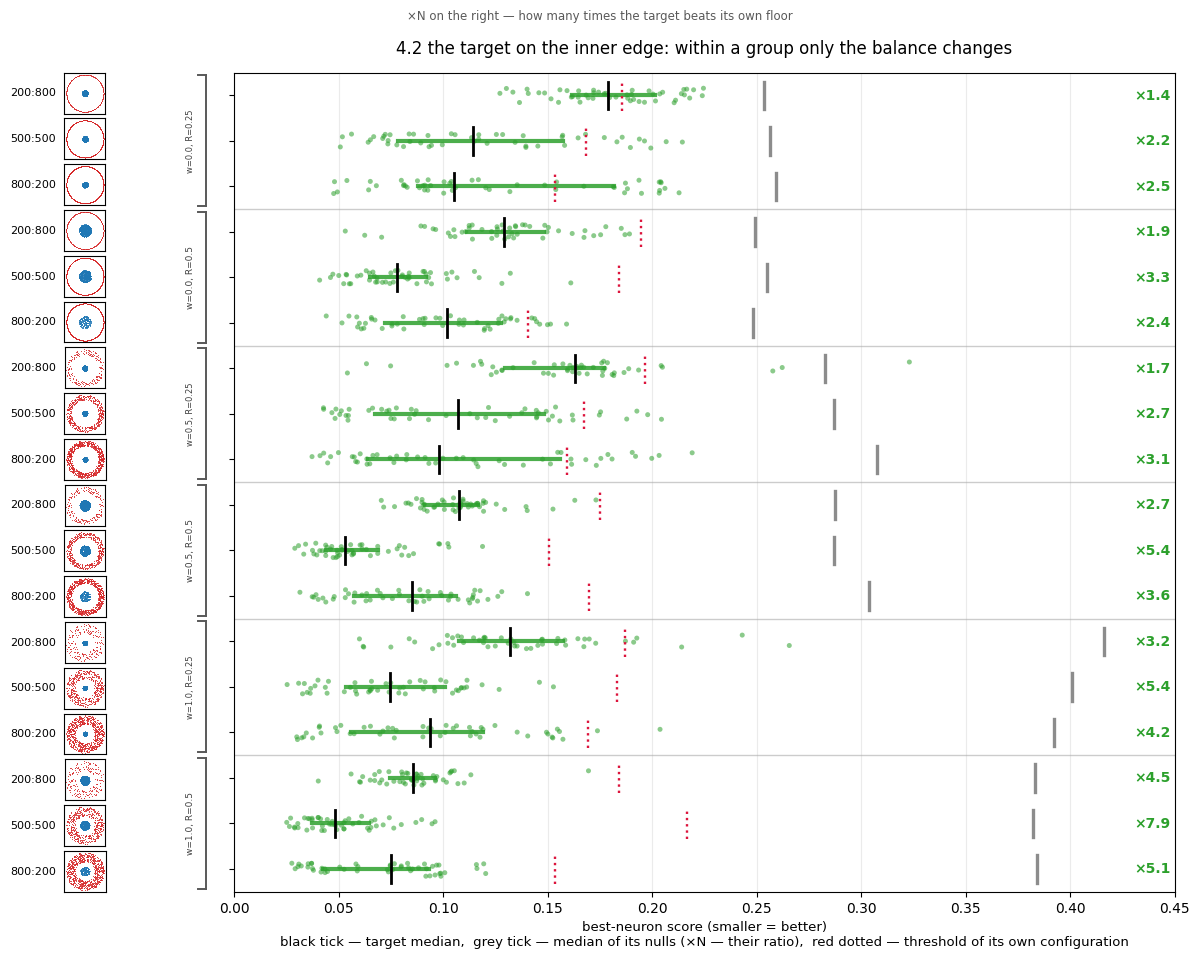

In [28]:
# All eighteen relevant cells; within a group only the balance changes.
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for w in W3:
    for R in (0.25, 0.5):
        for rho in RHO3:
            n, fam = C(task="relevant", w=w, R=R, rho=rho, T=1000)[0], FAM(w)
            b = best[(best.dataset_type == n) & (best.family == fam)]
            r = cells[(cells.cell == n) & (cells.family == fam)].iloc[0]
            nr = dsw.n_ring_of(rho, 1000)
            rows.append((f"{nr}:{1000-nr}", b[b.feature_role == "target"].score, dplt.CT))
            thumbs.append(n); thr.append(float(r.threshold))
            rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
        groups.append((f"w={w}, R={R}", 3))
fig = dplt.plot_strips(rows, xlim=(0, 0.45), row_thresholds=thr, height=0.42,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="4.2 the target on the inner edge: within a group only the balance changes",
    caption="×N on the right — how many times the target beats its own floor")
plt.show()

### What we see

**A starved feature is always the worst point.** `ρ = 0.25`, that is, 200 points on the ring against 800 on the disk,
gives the worst result **in all six lines**, both by the normalised score and by the dimensionless `×N`. This is the
only statement about this axis that holds without exceptions.

**The "optimum at equality", on the other hand, does not hold everywhere — in four lines of six.** In the remaining
two, and both of them have the small disk `R = 0.25`, the score keeps improving beyond `ρ = 1`: 0.1786 → 0.1142 →
0.1050 and 0.1630 → 0.1070 → 0.0981. `×N` behaves the same way there (1.42 → 2.24 → 2.47 and 1.73 → 2.68 → 3.14), so
the cause is neither the field nor the threshold.

**The exceptions are not accidental, and they add up to a rule.** Both fall on the small disk, and this is explicable:
an object needs as many points as are needed **for its size**. The spacing between the points of the disk `R = 0.25`
with 200 points is 0.031 — finer than that of the disk `R = 0.5` with 500 points (0.040). The small disk is already
resolved with 200 points, so there is nothing more to give it, and everything taken from it goes to the ring with
profit. For the large disk this reserve runs out, and the optimum returns to equality.

**The dimensionless ratio confirms the picture and removes the suspicion about the floor.** Together with the balance
the field changes, and with it the floor; the score could move not because the target is reproduced better but because
things got harder for a random component. `×N` is free of this — and gives the same order and the same exceptions.

**The witness fraction is the coarsest of the three readings.** In two lines it hit 1.00 at all three balances, so by
it the minimum falls on `ρ = 0.25` in only four lines of six. This axis should be read by the score and by `×N`.

### Conclusion

**An object needs as many points as its size requires, and starving the feature costs the most.** The score is
determined by whether the ring and the disk each have enough points; the worst point everywhere is a starved ring.
Where exactly the optimum lies depends on how large the disk is: with a small disk it pays to give points to the ring
even beyond equality.

**And how tightly the points are packed has nothing to do with it.** Along `ρ` at `w = 0.5` the spacing between the
ring's points goes 0.153 → 0.097 → 0.077, and the score behaves non-monotonically; along `w`, with the same point
counts, the spacing grows just as strongly, and on the stationary probe nothing changes. One and the same quantity in
one case "explains" a change, and in the other fails to explain its absence — so it is not the right quantity.

## 4.3 The disk axis: the radius of the interior

The third axis remains — the radius of the disk of the opposite class. It tests directly the thesis that the feature
and the interior are on an equal footing: if a relevant topological feature is formed by a pair, then the geometry of
the interior should give an effect comparable to the effect of the feature itself.

The disk radius takes two values, 0.25 and 0.5, so each line here is a segment of two points, and there are nine such
segments in all, one per combination `(w, ρ)`. The target is the verdict one, the inner edge: the width within a
segment is constant.

The gap between the disk and the ring is **not studied** in this experiment: by design it is kept at no less than 0.5
in all cells, and this is enough for the task to be solvable without sharp changes of value over a small distance. Here
it is a fixed condition, not a variable.

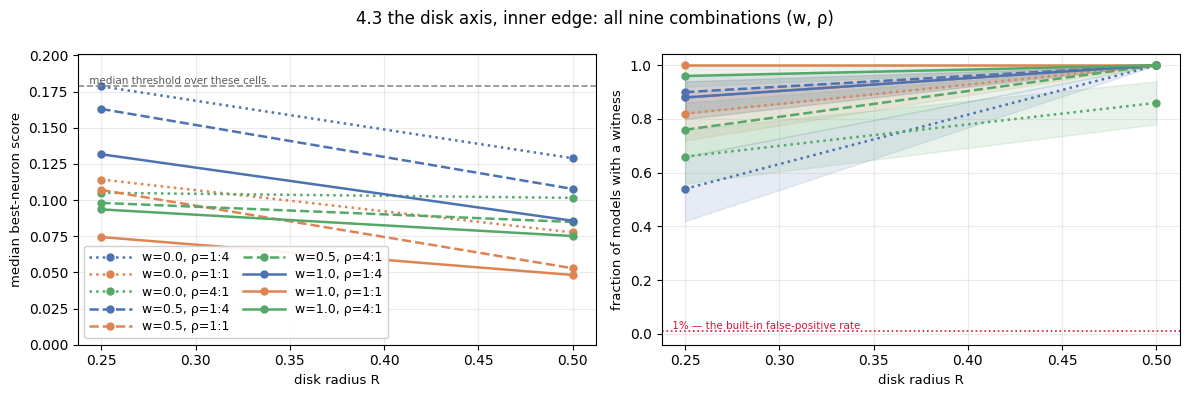

the larger disk is better in 9 cases of 9; median improvement 0.0365 (32%); by the dimensionless 'floor / target' — in 8 of 9
the threshold within a pair shifts by 0.0158 in median, upwards in 4 pairs of 9 — that is, with no sign
equal gap 0.75:  w=0.5 R=0.5 → abs. Chamfer 0.132, floor/target 5.43 | w=1.0 R=0.25 → abs. Chamfer 0.149, floor/target 5.38
equal gap 1.00:  w=0.5 R=0.25 → abs. Chamfer 0.267, floor/target 2.68 | w=0.0 R=0.5 → abs. Chamfer 0.233, floor/target 3.28


In [29]:
panels_R = [{"label": f"w={w}, ρ={ratio_label(r)}", "sel": {"w": w, "rho": r, "T": 1000},
             "colour": COL[r], "ls": {0.0: ":", 0.5: "--", 1.0: "-"}[w]}
            for w in W3 for r in RHO3]
# The anchor cell of experiment 1 sits at R = 1.0 and a different geometry; it has no place on this axis.
fig = dplt.plot_axis_panels(cells[cells.R < 1.0], "R", panels_R, family="edge",
    xlabel="disk radius R", suptitle="4.3 the disk axis, inner edge: all nine combinations (w, ρ)")
plt.show()

E18 = dsw.inner_edge(cw[(cw.task == "relevant") & (cw.R < 1.0) & (cw["T"] == 1000)])
piv = E18.pivot_table(index=["w", "rho"], columns="R", values="med_target")
pth = E18.pivot_table(index=["w", "rho"], columns="R", values="threshold")
prt = E18.pivot_table(index=["w", "rho"], columns="R", values="floor/target")
print(f"the larger disk is better in {int((piv[0.5] < piv[0.25]).sum())} cases of {len(piv)}; "
      f"median improvement {float((piv[0.25]-piv[0.5]).median()):.4f} "
      f"({float(((piv[0.25]-piv[0.5])/piv[0.25]).median()):.0%}); "
      f"by the dimensionless 'floor / target' — in {int((prt[0.5] > prt[0.25]).sum())} of {len(prt)}")
print(f"the threshold within a pair shifts by {float((pth[0.5]-pth[0.25]).abs().median()):.4f} in median, "
      f"upwards in {int((pth[0.5] > pth[0.25]).sum())} pairs of {len(pth)} — that is, with no sign")

# The gap 1.5 − w/2 − R coincides for two pairs of cells with different geometry: this is exactly
# the check whether the effect is exhausted by the width of the gap.
for cl, g in E18[E18.rho == 1.0].groupby("gap"):
    if len(g) > 1:
        cells_txt = " | ".join(f"w={r['w']} R={r['R']} → abs. Chamfer {r['abs_target']:.3f}, "
                               f"floor/target {r['floor/target']:.2f}" for _, r in g.iterrows())
        print(f"equal gap {cl:.2f}:  {cells_txt}")

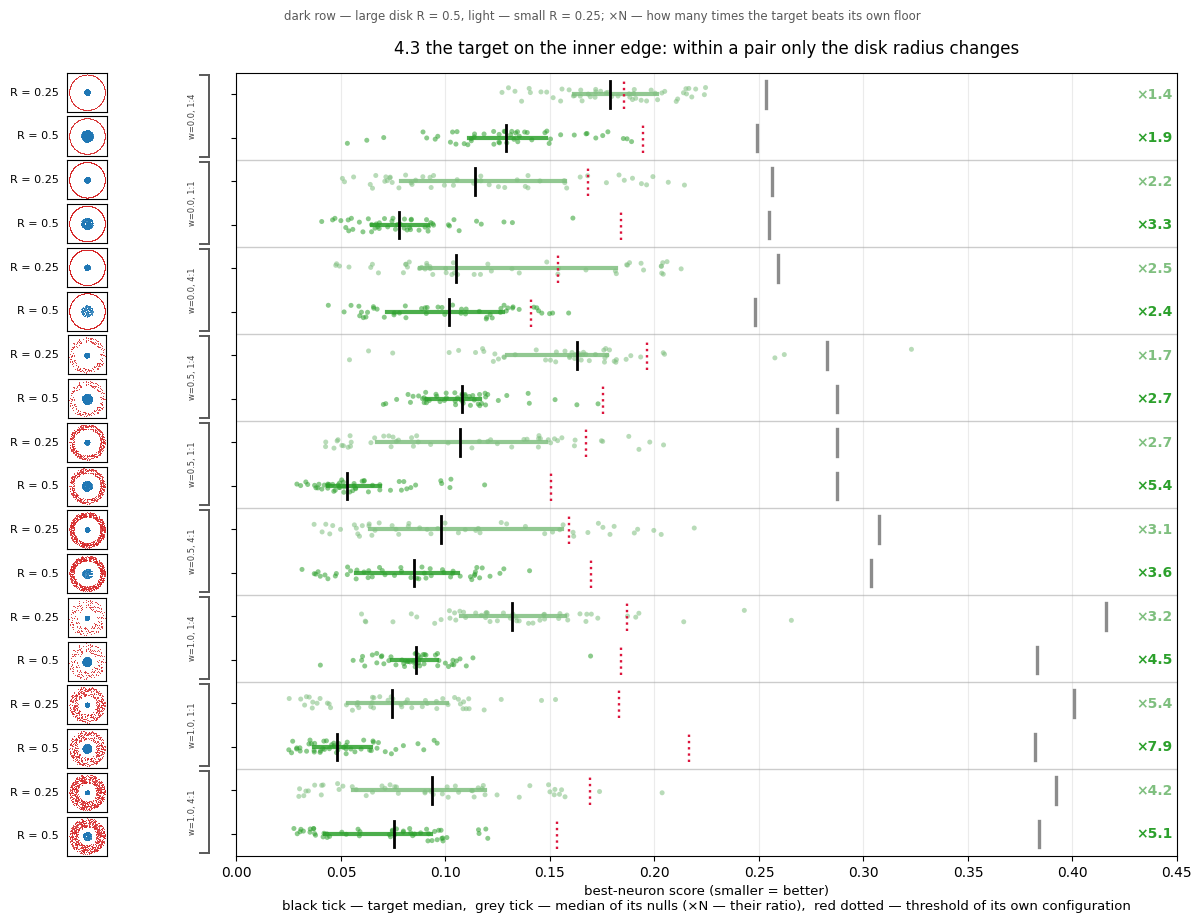

In [30]:
# Within a pair only the disk radius changes; everything else is held fixed.
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for w in W3:
    for rho in RHO3:
        for R in (0.25, 0.5):
            n, fam = C(task="relevant", w=w, R=R, rho=rho, T=1000)[0], FAM(w)
            b = best[(best.dataset_type == n) & (best.family == fam)]
            r = cells[(cells.cell == n) & (cells.family == fam)].iloc[0]
            rows.append((f"R = {R}", b[b.feature_role == "target"].score,
                         dplt.CT if R == 0.5 else "#7fbf7f"))
            thumbs.append(n); thr.append(float(r.threshold))
            rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
        groups.append((f"w={w}, {ratio_label(rho)}", 2))
fig = dplt.plot_strips(rows, xlim=(0, 0.45), row_thresholds=thr, height=0.40,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="4.3 the target on the inner edge: within a pair only the disk radius changes",
    caption="dark row — large disk R = 0.5, light — small R = 0.25; "
            "×N — how many times the target beats its own floor")
plt.show()

### What we see

**A larger disk gives a better witness, and this is visible in all three readings.** By the normalised score — in
**9 combinations of 9**; by the dimensionless `×N` — in 8 of 9, and the only exception (`w = 0, ρ = 4`) gives 2.44
against 2.47, that is, agreement within the second decimal; by the witness fraction — in 8 of 9 with one tie. The
median improvement of the score is 0.037, about a third of its size.

**The effect is consistent in sign — this is what distinguishes it from density.** The disk radius moves the score in
one and the same direction nine times out of nine, whereas a threefold thinning of the points on the stationary probe
(§4.1) does not move it at all.

**The floor, meanwhile, stays in place.** The threshold within a pair shifts by 0.016 in median — half the size of the
effect — and upwards in only four pairs of nine, that is, with no consistent sign. The medians of the nulls (the grey
ticks) within a pair also practically coincide. The disk does not change how hard it is to hit the circle by chance;
it changes only how well the trained network hits it.

### Conclusion

**The geometry of the interior is a working variable**, and it works in the same direction as the ring width in §4.1.

**Both axes do the same thing: they narrow the gap.** The gap between the feature and the interior equals
`1.5 − w/2 − R`; §4.1 narrows it by moving the inner edge towards the centre, §4.3 by inflating the disk outwards. The
zone in which the two objects of different classes interact lies **in this gap**, and the narrower it is, the more
tightly that zone is pressed against the inner edge — that is, against the target. Hence the agreement of signs: 6 rows
of 6 along the width, 9 pairs of 9 along the disk radius. Both supports are measurements of these two axes themselves;
the result of the balance axis (§4.2) does not enter here.

**This is a direct test of the thesis for the sake of which the inner edge became the target in the first place.** If a
relevant topological feature were a property of the feature alone, the disk radius should do nothing at all. If it is a
property of the **pair** — the feature plus the interior of the opposite class — then bringing either of the two objects
closer to the other should improve the picture at their contact. The second is observed, and it is observed from two
independent sides.

**But the gap is the mechanism, not the only variable.** Two pairs of cells have the same gap with different geometry,
and in both the one with the larger disk is no worse: at a gap of 1.00 the absolute Chamfer is 0.233 against 0.267 and
the ratio 3.28 against 2.68; at a gap of 0.75 it is 0.132 against 0.149 with practically equal ratios of 5.43 and 5.38.
The interior's own size takes part in addition to the width of the gap.

## Summary of task B

The three axes gave three different answers, and together they add up to one.

| axis | what it moves | effect |
|---|---|---|
| ring width `w` | the density of the feature **and** the gap at the same time | on the stationary probe **nothing** (a range of 0.003–0.023, no consistent sign); on the verdict target an improvement in 6 rows of 6, "floor / target" from 1.4–3.3 to 3.2–7.9 — and this is the gap, not density |
| balance `ρ` | the number of points of each of the two objects | **yes**: a starved feature is the worst point in 6 lines of 6, both by the score and by `×N`. The optimum at equality holds only in 4 of 6: with a small disk it pays to give points to the ring even beyond equality |
| disk radius `R` | the geometry of the interior, and with it the gap | **yes**, 9 of 9, about a third of the size of the score |

**The quality of the witness is determined by whether each object has enough points FOR ITS SIZE, and by the geometry of
the pair.** How tightly the feature is packed takes no part, either as a cause (task A) or as a modulator: on the
stationary probe its threefold change moves nothing.

**Two of the three axes turned out to be one axis — the gap axis.** The ring width and the disk radius narrow the gap
between the feature and the interior from different sides, and both improve the picture at the inner edge. This is
direct support for the thesis for the sake of which the inner edge became the target: a relevant topological feature is
a property of the **pair**, and what works is the zone of their contact. §2.8 agrees with this as well: the structure
was found exactly there.

**A check on a different target.** The balance and disk axes are also computed on the middle circle: the larger disk is
better in 9 cases of 9, the median improvement is 24% (against 32% on the inner edge), the balance optimum is at
`ρ = 1` in 5 lines of 6. The conclusion does not depend on the choice of target; only the magnitude changes.

**One caveat about what is NOT separated here.** The disk radius changes its geometry, its areal density and the gap
alike. The pairs matched by gap show that the effect is not exhausted by the gap, but the geometry and the density of
the disk are not separated on this grid, and the statement is formulated about the radius as such.

---

# 5. Task C — density or number of points?

**Question.** Task B answered "the number of points" on its grid. Here the answer is checked where it could break: with
a five times larger sample, where the absolute level of density is different but its ratio between the objects is the
same.

**Why it is needed.** The statement "the number of points is what works" has two different readings, and here they
diverge. The first: what matters is the **absolute** size of the sample, and then `T = 5000` should improve everything
noticeably. The second: what matters is **sufficiency** — whether there are enough points for the object to be
distinguishable — and then the improvement should hit a ceiling.

**How we check.** The target is the verdict one, the inner edge; `T = 5000` instead of 1000 with the geometry unchanged:
both densities grow at once, their ratio is preserved. The slice is the balance axis at both non-zero widths, in both
tasks, for task-relevant at `R = 0.5`. **12 cells.**

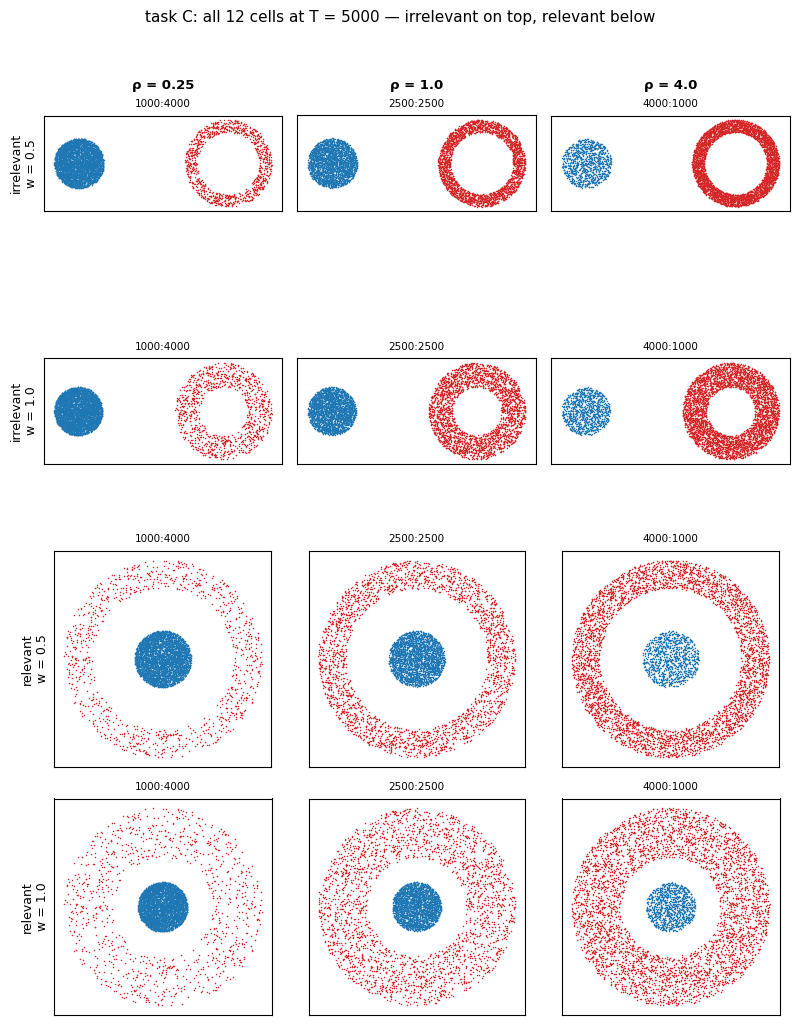

In [31]:
fig = dplt.plot_dataset_grid(BIG, dsw.dataset_points, ncols=3, size=2.4, label_of=label,
    row_labels=["irrelevant\nw = 0.5", "irrelevant\nw = 1.0",
                "relevant\nw = 0.5", "relevant\nw = 1.0"],
    col_labels=[f"ρ = {r}" for r in RHO3],
    title="task C: all 12 cells at T = 5000 — irrelevant on top, relevant below")
plt.show()

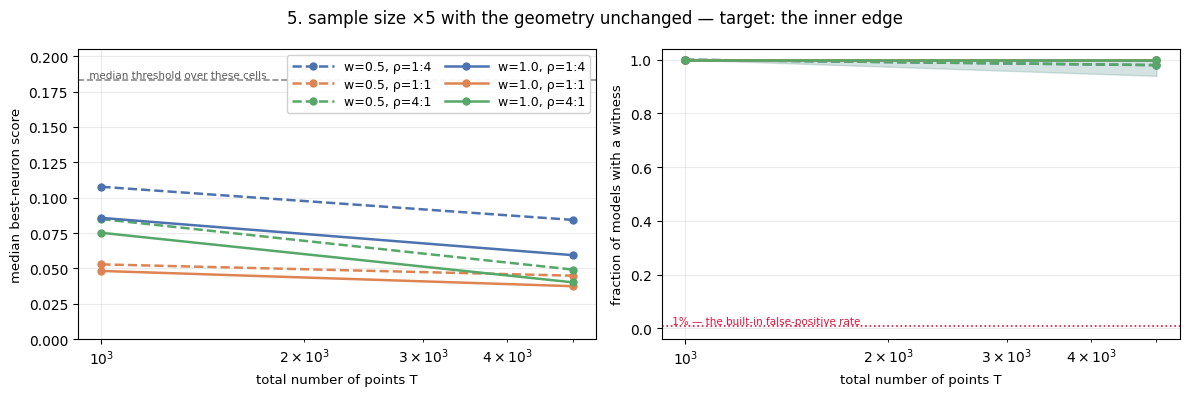

the score improved in 6 pairs of 6, shift 0.0080..0.0357
fraction: was 1.00-1.00, became 0.98-1.00


In [32]:
panels_T = [{"label": f"w={w}, ρ={ratio_label(r)}", "sel": {"w": w, "rho": r, "R": 0.5},
             "colour": COL[r], "ls": "-" if w == 1.0 else "--"}
            for w in (0.5, 1.0) for r in RHO3]
fig = dplt.plot_axis_panels(cells, "T", panels_T, family="edge", logx=True,
    xlabel="total number of points T",
    suptitle="5. sample size ×5 with the geometry unchanged — target: the inner edge")
plt.show()

S = EDGE[(EDGE.task == "relevant") & (EDGE.R == 0.5) & (EDGE.w > 0)]
p5 = S.pivot_table(index=["w", "rho"], columns="T", values="med_target")
r5 = S.pivot_table(index=["w", "rho"], columns="T", values="rate")
print(f"the score improved in {int((p5[5000] < p5[1000]).sum())} pairs of {len(p5)}, "
      f"shift {float((p5[1000]-p5[5000]).min()):.4f}..{float((p5[1000]-p5[5000]).max()):.4f}")
print(f"fraction: was {r5[1000].min():.2f}-{r5[1000].max():.2f}, became {r5[5000].min():.2f}-{r5[5000].max():.2f}")

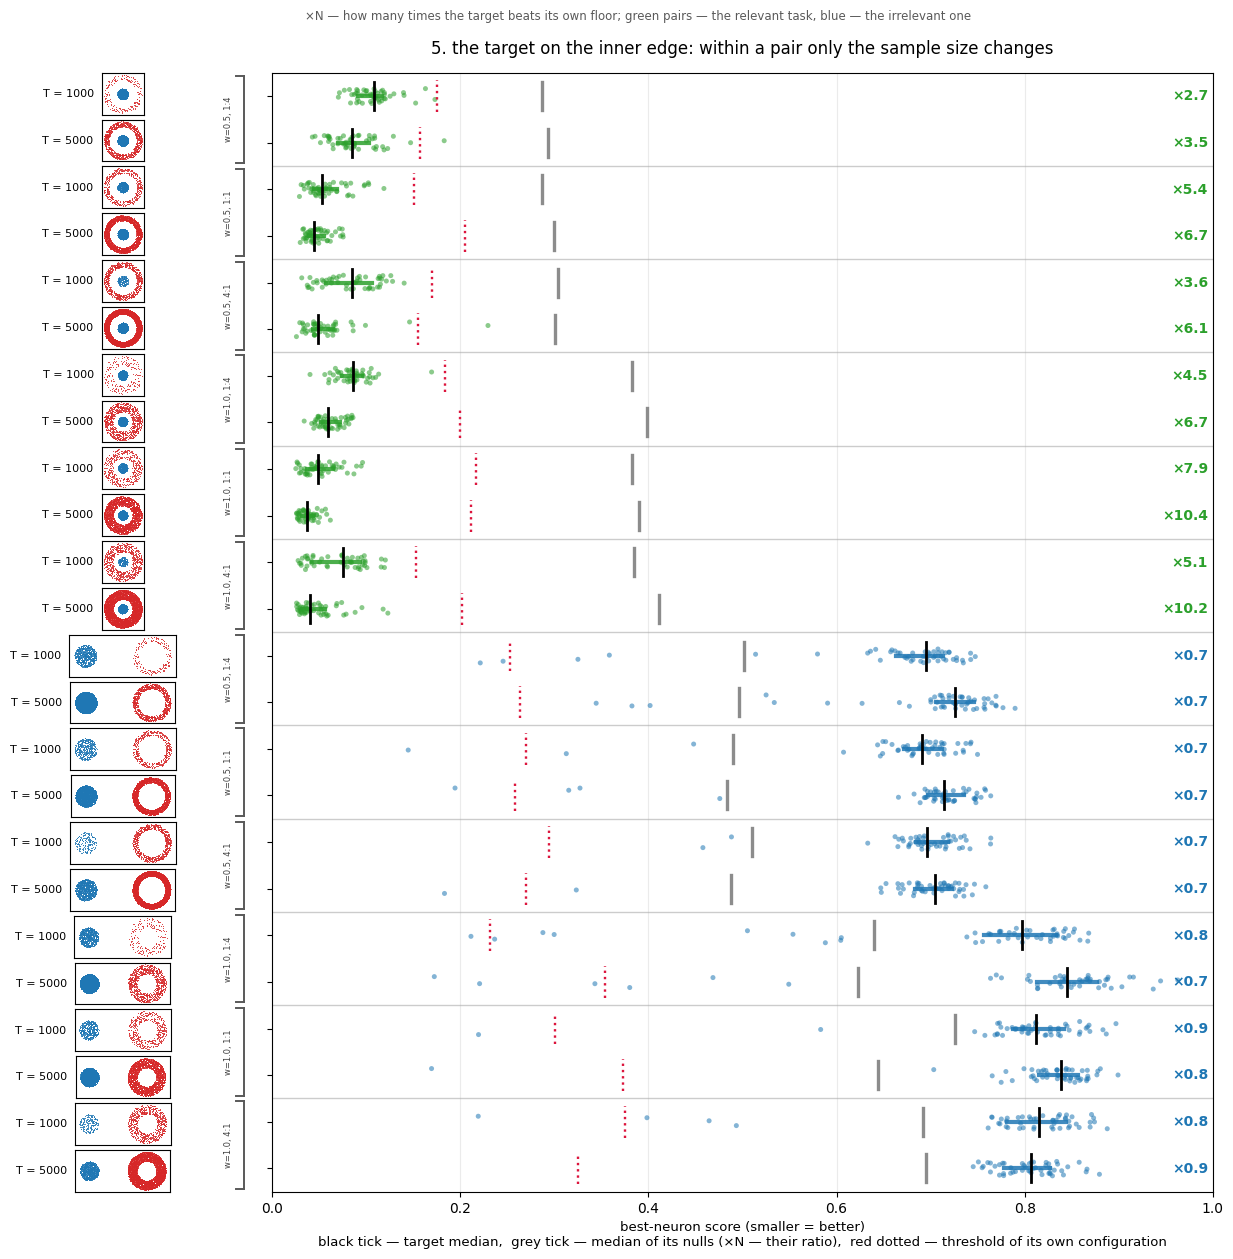

In [33]:
# A pair of rows = one geometry at two sample sizes; configurations are not mixed.
rows, thr, thumbs, groups, rat, nul = [], [], [], [], [], []
for task, col in (("relevant", dplt.CT), ("irrelevant", dplt.C1)):
    for w in (0.5, 1.0):
        for rho in RHO3:
            for T in (1000, 5000):
                sel = (C(task=task, w=w, rho=rho, T=T) if task == "irrelevant"
                       else C(task=task, w=w, R=0.5, rho=rho, T=T))
                n, fam = sel[0], FAM(w)
                b = best[(best.dataset_type == n) & (best.family == fam)]
                r = cells[(cells.cell == n) & (cells.family == fam)].iloc[0]
                rows.append((f"T = {T}", b[b.feature_role == "target"].score, col))
                thumbs.append(n); thr.append(float(r.threshold))
                rat.append(float(r.med_null / r.med_target)); nul.append(float(r.med_null))
            groups.append((f"w={w}, {ratio_label(rho)}", 2))
fig = dplt.plot_strips(rows, xlim=(0, 1.0), row_thresholds=thr, height=0.44,
    thumbs=thumbs, loader=dsw.dataset_points, groups=groups, ratios=rat, null_medians=nul,
    title="5. the target on the inner edge: within a pair only the sample size changes",
    caption="×N — how many times the target beats its own floor; green pairs — the relevant task, "
            "blue — the irrelevant one")
plt.show()

### What we see

**A five times larger sample improves the score but does not change the verdict.** The median shifts by 0.008–0.036 and
improves in all six pairs — that is, there is an effect and it is consistent in sign, unlike the effect of density. But
the witness fraction was 1.00 and became 0.98–1.00: it has nowhere left to move. The lines in the left panel are almost
horizontal on the logarithmic scale — a fivefold increase of the sample does less than moving the same points between
the objects in §4.2 (where the range within a line is 0.038–0.074).

**The shape of the dependence on the balance is preserved.** At `T = 5000` the order is exactly the same: `ρ = 0.25` is
the worst of all. So the point is not the absolute numbers but that each object should have enough points.

**On the task-irrelevant side a five times larger sample gives nothing at all**: a fraction of 0.00–0.06, the rows of
the populations coincide with those at `T = 1000` to the thickness of a line, and the target is still worse than its
own floor.

### Conclusions

**The "sufficiency" reading is the right one, not the "absolute level" one.** Points are needed for the object to be
distinguishable; after that, adding more points improves the score a little, but the verdict is already saturated,
while moving points between the objects moves it more. This is exactly why the balance turned out stronger than the
sample size.

**And this is the third, independent way in which density was not confirmed.** In task A it was changed on the
irrelevant task, in §4.1 on the relevant one at constant point counts, here both densities were raised at once. None of
them gave an effect in favour of the density hypothesis.

---

# 6. Task F — what the second criterion says

**Question.** Everything so far has been measured with one instrument. The homological criterion asks a different
question about the same neurons — **whether there is a closed loop at all** in the field near the feature — and the
agreement or disagreement of the two instruments is informative in itself.

**Why it is needed.** First, a conclusion resting on one criterion is weaker than a conclusion confirmed by a second,
independent one. Second — and this is more important — the criteria ask **different** things: the structural one
measures how accurately a level set fits **onto the target**, the homological one whether a loop exists in its
neighbourhood. If the geometry moves the first and does not move the second, then what changes is not the presence of
the loop but its position, and this is a direct answer to the question left open in §2.8.

**How the criterion works.** On the point cloud near the target a superlevel persistence is built (both orientations of
the field), and the longest bar in `H_1` is taken. The quantity `persistence_margin` is how far it exceeds the next bar
and the absolute floor of 10% of the range of the field. **`margin > 0` means "there is a dominant loop"**; a negative
value means there are bars, but none dominates; `NaN` means there are no bars at all.

**Three caveats without which the numbers are read wrongly.**

*The first.* The criterion looks at a **neighbourhood** of the target (1.5 of its radius), not at the curve itself. So
it does not know where exactly the loop runs — only that it is somewhere nearby. This is not a flaw but a division of
labour: that is exactly why it complements the structural criterion rather than duplicating it.

*The second.* The neighbourhood grows together with the radius of the target, so `margin` **cannot** be compared
between different targets — only between cells at one and the same target. Everything below is computed on the verdict
target.

*The third.* Layer 0 is excluded: its level sets are straight lines, a loop cannot occur there by theorem, and including
it would only dilute the fractions with zeros.

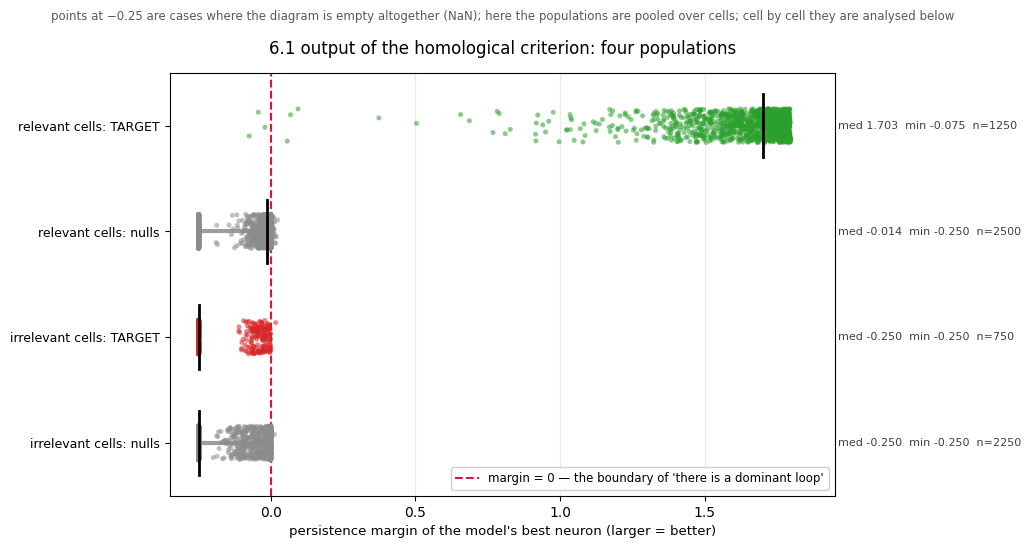

                         units  fraction_with_loop  median_margin
task       feature_role                                          
irrelevant null           2250               0.003         -0.011
           target          750               0.001         -0.039
relevant   null           2500               0.014         -0.005
           target         1250               0.998          1.703

task A cell by cell — fraction of models with a loop on the irrelevant target:
rho  0.25  1.00  4.00
w                    
0.0   0.0  0.00   0.0
0.5   0.0  0.02   0.0
1.0   0.0  0.00   0.0


In [34]:
hom  = dsw.homology_units(dsw.inner_edge(df))       # (cell, feature, model) -> best margin
homc = dsw.homology_cells(hom)                      # the same, aggregated by cell

rows = [(lab, hom[(hom.task == t) & (hom.feature_role == r)].margin.fillna(-0.25), col)
        for t, r, lab, col in (
            ("relevant",   "target", "relevant cells: TARGET",   dplt.CT),
            ("relevant",   "null",   "relevant cells: nulls",    dplt.CN),
            ("irrelevant", "target", "irrelevant cells: TARGET", dplt.C0),
            ("irrelevant", "null",   "irrelevant cells: nulls",  dplt.CN))]
fig = dplt.plot_strips(rows, xlim=(-0.35, 1.95), height=0.9,
    vline=(0.0, "margin = 0 — the boundary of 'there is a dominant loop'"),
    xlabel="persistence margin of the model's best neuron (larger = better)",
    title="6.1 output of the homological criterion: four populations",
    caption="points at −0.25 are cases where the diagram is empty altogether (NaN); "
            "here the populations are pooled over cells; cell by cell they are analysed below")
plt.show()

print(hom.groupby(["task", "feature_role"])
         .agg(units=("witness", "size"), fraction_with_loop=("witness", "mean"),
              median_margin=("margin", "median")).round(3).to_string())
print("\ntask A cell by cell — fraction of models with a loop on the irrelevant target:")
A = homc[(homc.task == "irrelevant") & (homc.feature_role == "target") & (homc["T"] == 1000)]
print(A.pivot_table(index="w", columns="rho", values="rate").round(3).to_string())

### What we see

**The output of the criterion is almost binary.** On the relevant targets the model's best neuron gives a margin of
about 1.6–1.8, and **there is a loop in 998 models of 1000**. In all three other populations the margin is negative or
the diagram is empty: for the nulls of the relevant cells a loop is found in 1.4% of cases, for the irrelevant targets
**in 0.1%** (one model of 750), for their nulls in 0.3%. There is almost no intermediate zone: either the loop is
there and it is dominant, or it is not there at all.

**Task A is closed by the second instrument too, and more firmly.** Over the nine irrelevant cells the fraction is zero
everywhere except one cell, where it is 0.02. Neither the ring width nor the balance moves it. The structural criterion
gave 0.00–0.04 there — that is, **both instruments say "there is no loop", and density does not create one**.

**And this is the same result in a stronger form.** The structural criterion could have stayed silent because the loop
is there but runs somewhere other than where we look. The homological one leaves no such loophole: it looks at the
whole neighbourhood and finds no loop there. On the irrelevant dataset the network does not build closed structures
around the ring at any density.

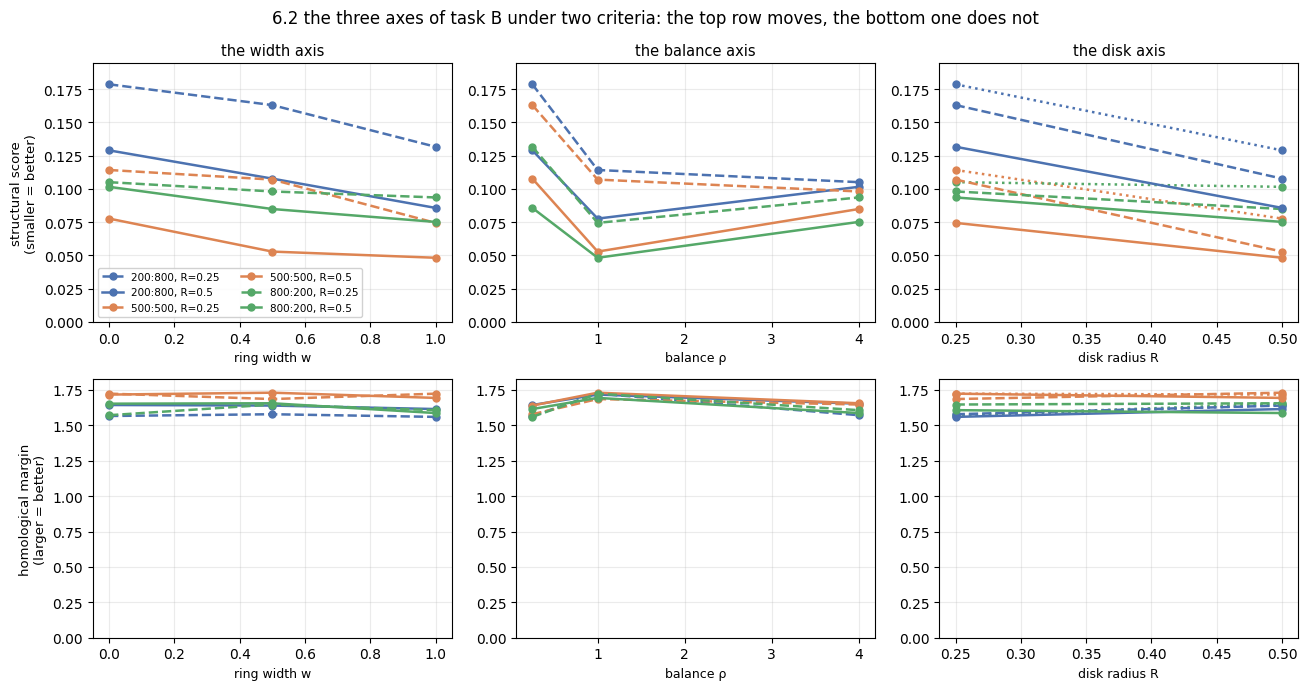

structural score over 18 cells: 0.048-0.179 (a 3.7-fold range)
homological margin:             1.560-1.731 (a 1.11-fold range)
neurons with a loop per model:  13-16 of 20 (this quantity did not reach its ceiling, so the cause is not saturation)


In [35]:
# The same three axes of task B, but each one read with two criteria at once.
S = dsw.inner_edge(cells)
S = S[(S.task == "relevant") & (S.R < 1.0) & (S["T"] == 1000)]
H = dsw.inner_edge(homc[homc.feature_role == "target"])
H = H[(H.task == "relevant") & (H.R < 1.0) & (H["T"] == 1000)]

AXES = [
    {"axis": "w",   "xlabel": "ring width w", "title": "the width axis",
     "panels": [{"label": f"{dsw.n_ring_of(r,1000)}:{1000-dsw.n_ring_of(r,1000)}, R={R}",
                 "sel": {"rho": r, "R": R}, "colour": COL[r],
                 "ls": "-" if R == 0.5 else "--"} for r in RHO3 for R in (0.25, 0.5)]},
    {"axis": "rho", "xlabel": "balance ρ", "title": "the balance axis",
     "panels": [{"label": f"w={w}, R={R}", "sel": {"w": w, "R": R},
                 "colour": {0.0:"#4c72b0",0.5:"#dd8452",1.0:"#55a868"}[w],
                 "ls": "-" if R == 0.5 else "--"} for w in W3 for R in (0.25, 0.5)]},
    {"axis": "R",   "xlabel": "disk radius R", "title": "the disk axis",
     "panels": [{"label": f"w={w}, ρ={ratio_label(r)}", "sel": {"w": w, "rho": r},
                 "colour": COL[r], "ls": {0.0:":",0.5:"--",1.0:"-"}[w]}
                for w in W3 for r in RHO3]},
]
fig = dplt.plot_criteria_axes(S, H, AXES,
    title="6.2 the three axes of task B under two criteria: the top row moves, the bottom one does not")
plt.show()

print(f"structural score over 18 cells: {S.med_target.min():.3f}-{S.med_target.max():.3f} "
      f"(a {S.med_target.max()/S.med_target.min():.1f}-fold range)")
print(f"homological margin:             {H.med_margin.min():.3f}-{H.med_margin.max():.3f} "
      f"(a {H.med_margin.max()/H.med_margin.min():.2f}-fold range)")
print(f"neurons with a loop per model:  {H.med_n_positive.min():.0f}-{H.med_n_positive.max():.0f} of 20 "
      f"(this quantity did not reach its ceiling, so the cause is not saturation)")

### What we see

**The top row moves, the bottom one stands still.** Over the same eighteen cells the structural score goes from 0.048
to 0.179 — a **3.7-fold** range; the homological margin from 1.560 to 1.731 — a **1.11-fold** range. None of the three
axes moves the second criterion to any noticeable degree: the fraction of models with a loop is 1.00 in sixteen cells
of eighteen and 0.96–0.98 in the remaining two.

**And this is not a saturation of the scale.** One could object that the margin of the best neuron has simply hit a
ceiling. But there is a second, unsaturated reading — how many of a model's neurons carry the loop: it gives 13–16 of
twenty, that is, far from the ceiling, and it too barely moves across cells.

**A weak echo of the balance is present after all.** The maximum of the margin falls on `ρ = 1` (1.69–1.73 against
1.56–1.66 at the ends), that is, the same shape as that of the structural score, but twenty times weaker in relative
terms. This is to be expected: for a loop to be built at all, both objects must have enough points.

**The disk axis does not act on the homological criterion** — 1.56–1.72 at `R = 0.25` against 1.59–1.73 at `R = 0.5` —
whereas it moves the structural score in nine pairs of nine. The same pattern as for trainability (the appendix):
quantities that change the **place** of the boundary do not change the fact of its existence.

**Task C, for completeness.** At `T = 5000` the margin rises 1.59–1.73 → 1.78–1.79, consistently in all six pairs, while
the fraction stays 1.00. More points — cleaner topology, but the verdict was saturated and has stayed so.

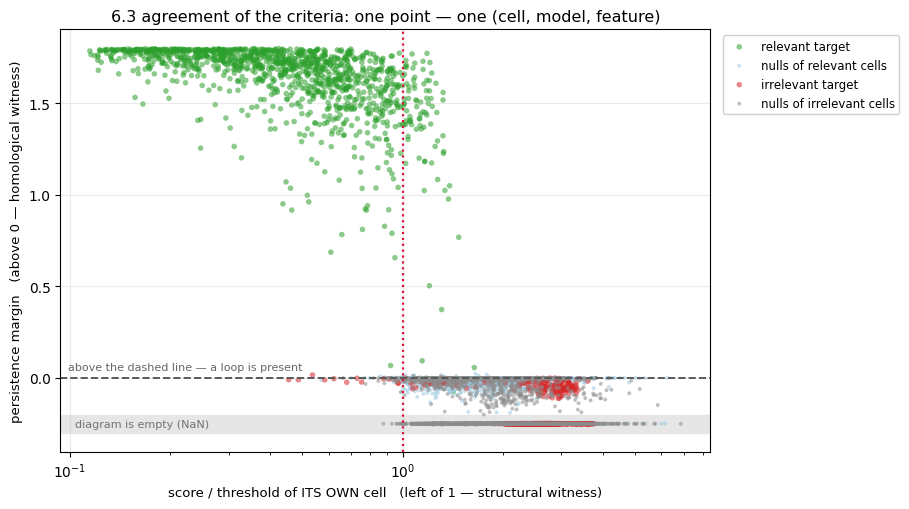

relevant   target n= 1250:  both  1161 | structural only    0 | homological only   86 | neither     3
relevant   null   n= 2500:  both     7 | structural only   18 | homological only   27 | neither  2448
irrelevant target n=  750:  both     1 | structural only   12 | homological only    0 | neither   737
irrelevant null   n= 2250:  both     1 | structural only   29 | homological only    6 | neither  2214

at the level of NEURONS (relevant targets, layers 1-4, 25000 of them): structural 0.572, homological 0.704; structural WITHOUT a loop 14 of 14295


In [36]:
# Agreement of the two criteria; the unit of observation is (cell, model, feature).
u = hom.merge(best.rename(columns={"score": "struct_score"})[["dataset_type", "feature_name",
              "model_path", "struct_score"]],
              on=["dataset_type", "feature_name", "model_path"], how="left")
thr = {(r.cell, r.family): r.threshold for r in cells.itertuples()}
u["score_over_threshold"] = [s / thr.get((c, f), np.nan)
                             for s, c, f in zip(u.struct_score, u.dataset_type, u.family)]
u["struct"] = u.score_over_threshold <= 1.0

fig = dplt.plot_criteria_scatter(u, title="6.3 agreement of the criteria: one point — one (cell, model, feature)")
plt.show()

for task in ("relevant", "irrelevant"):
    for role in ("target", "null"):
        b = u[(u.task == task) & (u.feature_role == role)]
        both = int((b["struct"] & b.witness).sum()); so = int((b["struct"] & ~b.witness).sum())
        ho = int((~b["struct"] & b.witness).sum()); nn = int((~b["struct"] & ~b.witness).sum())
        print(f"{task:10s} {role:6s} n={len(b):5d}:  both {both:5d} | structural only {so:4d} | "
              f"homological only {ho:4d} | neither {nn:5d}")
n = dsw.inner_edge(df)
n = n[(n.layer_id > 0) & (n.task == "relevant") & (n.feature_role == "target")].copy()
n["struct"] = [s <= thr.get((c, f), np.nan) for s, c, f in zip(n.score, n.dataset_type, n.family)]
n["homol"] = (n.margin > 0).fillna(False)
print(f"\nat the level of NEURONS (relevant targets, layers 1-4, {len(n)} of them): "
      f"structural {n['struct'].mean():.3f}, homological {n['homol'].mean():.3f}; "
      f"structural WITHOUT a loop {int((n['struct'] & ~n['homol']).sum())} of {int(n['struct'].sum())}")

### What we see

**A structural witness is almost always a subset of a homological one.** On the relevant targets, out of 1250
(cell, model) pairs both criteria fired for 1161, only the homological one for 86, **only the structural one for
none**, and neither for three. At the level of individual neurons it is the same: 14 violations in 14,295 structural
witnesses, that is, 0.1%. In other words: **if a level set has fallen onto the target, there is certainly a loop
there**; the converse is false.

**Those very 86 are the case "there is a loop, but not on the target".** They are not scattered over the grid but
gathered in one corner of it: 77 of 86 fall on the small disk `R = 0.25`, 61 of 86 on `w = 0`. This is exactly the
corner where the structural score is worst (§4.3) and where fewer than half of the models pass the verdict (§4.1). So
there the network builds a closed structure but does not run it along the inner edge.

**On the irrelevant task the homological criterion is stricter than the structural one.** It has 1 false firing of 750
against 13 of 750 for the structural one. The few "detections" that the structural criterion does not remove at any
threshold (§2.7) almost all turn out to be cases where there is no loop at all.

### Conclusion

**Both criteria give the same verdict about density, and this makes the conclusion of the experiment stronger.**
Density does not create a loop where the task does not require it (0.001 against 0.998), and does not improve it where
the task does.

**But they speak about different things, and the difference turned out to be meaningful.** Topology — whether there is
a closed structure — is present whenever the task forces it and does not appear when it does not; it reacts neither to
the ring width nor to the disk radius. Geometry — where exactly this structure runs — is changed by all the geometric
variables at once.

**This directly answers the question left open in §2.8.** The observation "the structure is closer to the inner edge"
could not be an artefact of the loop being absent somewhere: the loop is there almost everywhere and almost always.
What changes with geometry is its position. And this also explains why §4.1 and §4.3 move the structural score while
trainability (the appendix) and the homological criterion are indifferent to them: the gap changes the **place** of the
boundary without changing either the fact of its existence or the difficulty of the task.

---

# 7. What has been established

**The density of the feature's points takes no part in the appearance of a witness neuron — neither as a cause nor as a
modulator.** Three independent ways of checking this, and none gave an effect in its favour:

* it **does not create** a witness where the task does not see the feature (task A: a fraction of 0.00–0.06 with a
  median of 0.02 in all 15 irrelevant cells, at a threshold that lets through 1% of the nulls; moreover, the target
  there is **worse** than its own nulls in all 15, the median `p_superior` = 0.18 with an interval of
  `[0.14, 0.27]`);
* it **does not improve** a witness where the feature is needed (§4.1: on the probe standing at a fixed radius, a
  threefold thinning of the ring's points does not move the median — a range within a row of 0.003–0.023 with no
  consistent sign, against 0.121 between the rows. And where the score does move — on the target that moves together
  with the feature — it moves in the direction OPPOSITE to the density hypothesis: the feature becomes three times
  sparser, while the ratio "floor / target" doubles);
* its **absolute level** decides nothing (task C: a fivefold rise of both densities at once moves the median by
  0.008–0.036 and does not change the verdict — the fraction was 1.00 and stayed 0.98–1.00; and this is a rise not only
  of the densities but also of the point counts, that is, the same sufficiency effect as in §4.2).

**The second criterion gives the same verdict, and gives it more firmly.** The homological `persistence_margin` finds a
dominant loop in 998 models of 1000 on the relevant targets and in only 1 of 750 on the irrelevant ones; along both axes
of task A it is zero everywhere except one cell at 0.02. The structural criterion could have stayed silent because the
loop runs somewhere other than where we look; the homological one leaves no such loophole — it looks at the whole
neighbourhood and finds no loop there.

**The confound that the experiment was set up for is closed.** The conclusions of experiments 1 and 2 that the witness
appears because of relevance require no correction for the density of the sample.

**What instead of density.** The number of points of each of the two objects — the score is best at equality and
degrades when either one is starved, with starving the feature itself doing more harm (the worst point with a starved
ring in 6 lines of 6, both by the score and by the dimensionless "floor / target") — and **the geometry of the pair**:
the gap between the feature and the interior. Both variables move the score consistently in sign, which density does
not do even once.

**The gap is what actually stands behind two of the three axes.** The ring width narrows it by moving the inner edge
towards the centre (the normalised score improves in 6 rows of 6, the ratio "floor / target" grows from 1.4–3.3 to
3.2–7.9 — even though along this axis the normalisation plays against an improvement), the disk radius narrows it from
the other side, by inflating the interior (9 pairs of 9). The zone where the two objects of different classes interact
lies in this gap, and the narrower it is, the more tightly that zone is pressed against the inner edge. The pairs
matched by gap show that the effect is not exhausted by the gap: at equal gap the cell with the larger interior is no
worse. **A relevant topological feature is a property of the pair, not of the feature alone** — and this is measured
from two independent sides.

**The structure sits at the inner edge of the feature**, at the contact with the interior of the opposite class. A
bracket of three concentric probes gives 5.38 → 2.32 → 1.14 in the ratio "floor / target" from the inner edge to the
outer at `w = 1.0` (and 3.48 → 2.32 → 1.60 at `w = 0.5`), in 18 configurations of 18 and in all three units of
measurement. This receives no causal reading: the contact with the interior and the loss of roundness of a "cap" with
distance from its extremum predict the same thing here, and the ring and the disk are concentric in all forty cells.
Telling them apart is the question of experiment 5.

**The task is visible at the output of the network as well.** The head witnesses the relevant target in 100 cases of
100 and is silent on all 47 irrelevant targets and on 802 nulls of 803.

**Topology is present whenever the task requires it; only its position changes.** Over the same eighteen cells the
structural score spans a 3.7-fold range, the homological margin a 1.11-fold one; the fraction of models with a loop is
1.00 in sixteen cells of eighteen. Neither the ring width nor the disk radius acts on the second criterion. And the
structural witness turns out to be a **subset** of the homological one: on the relevant targets 1161 models passed both
criteria, 86 only the homological one, and **none only the structural one**. Those 86 are gathered in one corner of the
grid (77 of 86 at the small disk), and this is exactly the corner where the structural score is worst. So there the
network builds a closed structure but does not run it along the inner edge.

**Trainability is a second instrument on the same grid.** Along the balance and the width it responds to the same
variables and in the same direction as the score; along the disk radius it does not respond at all, and this is
informative in itself: the disk changes not the difficulty of the task but the place where the boundary runs.

**The link with experiment 1 holds.** The anchor cell with its geometry (a circle of 500 points around a disk `r = 1.0`
of 500 points), recomputed in the new box, reproduced its numbers: the median best neuron 0.0314 against 0.0349, a
witness in 50 models of 50 against 49 of 50, `p_superior = 1.0000`.

## What carries over to the next experiments

* **The verdict target is the inner edge of the feature**; the middle circle is needed only where a trend is measured
  along an axis on which the inner edge moves. The ring is not to be taken as a target — because of its low
  discriminating power (1.57 against 4.79 for the inner edge). The outer circle carries no question of its own (1.19,
  in places worse than chance).
* **A target is a sample of a region of space, not a subset of the training sample**, and its spacing is a parameter
  of the instrument: `δ(A) < h` is required. Checked by measurement: the ceilings of the three circles are
  0.0337 / 0.0342 / 0.0360 at `h/2 = 0.0339`.
* **The threshold is taken from the target's own nulls in its own cell** — the **1st percentile**, over the whole floor
  of that cell — and is not inherited. τ = 0.1 from experiments 1 and 2 does not apply here: the thresholds of the
  verdict target run 0.14–0.38 across the forty cells.
* **The verdict has two parts**: the score below the threshold AND a witness that has survived the composition all the
  way to the head. The first condition lets through 296 false firings, the second lets through none.
* **Targets of different size are comparable only by dimensionless ratios** — "floor / target" and "achieved /
  ceiling"; the raw normalised score is no good for this.
* **The two criteria are read on the same rows and answer different questions**: the homological one whether there is
  a closed structure, the structural one where it runs. The margin cannot be compared between targets: the criterion
  looks at a neighbourhood of 1.5 radii of the target, and the neighbourhood grows together with it.
* **Density can be struck off the list of confounds**; in its place, the number of points of an object and the geometry
  of the interior go onto the list of working variables.
* **Measure the floor in its own cell and by placement**, not as a single number: the median floor over the three
  placements runs 0.46 / 0.58 / 0.67 — a spread of up to a third of the value.
* **The training success rate is reported as a result.**

## Limits of applicability

* **Whether there is a witness and how good it is — yes; where exactly it stands — only coarsely.** The structural
  criterion is a minimum over levels; the localisation of §2.8 was obtained with a bracket of three probes, not by
  measuring the position of a level set.
* **The width axis gives two unequal steps.** The thinning from `w = 0` to `0.5` is stronger than from `0.5` to `1.0`;
  along this axis one should read the presence and the sign of an effect, not its slope.
* **The disk axis is not decomposed.** The radius changes the geometry of the interior, its areal density and the gap
  at the same time; the gap is kept above 0.5 by design and is not treated as a variable, but the geometry and the
  density of the disk are not separated on this grid.
* **The verdict's floor rests on two null placements** — on the task-relevant side there is no corridor.
* **A percentile is the name of a rule, not a measured error rate** (§2.7): outside the sample of nulls on which it was
  set, it is realised roughly two to three times more often than the nominal.
* **The ensembles are conditioned on passing the gate**, and in the worst cells this is noticeable (§6).
* **Alignment, not encoding.** There is no ablation here, as there was none in experiments 1 and 2; the intervention is
  only in the data, not in the network.
* **One feature shape, one activation, one architecture.** The absolute levels of the floor do not transfer to other
  tasks; the method does.

---

# Appendix. Task E — the trainability of a cell as a second outcome

*This task is not part of the main line A → B → C → F: it arose from the run itself, not from the plan, and it measures
not neurons but how often a random initialisation reaches the gate. It is moved to the appendix so as not to break the
narrative; §6 and §7 refer to its result.*

**Question.** The gate of the experiment is 100% test accuracy. The server run showed that in some cells not all
initialisations reach it. Is this scheduling noise or a measurement?

**Why it is needed.** The task did not come from the plan — the run itself brought it. But it falls exactly into the
subject of the experiment: if the task stops **firmly** forcing a closed boundary, this should be visible not only in
the score of the neurons but also in how often a random initialisation reaches perfect separation. That is, it is a
second instrument measuring the same thing.

**How we check.** The fraction of the 50 initialisations that reached the gate on the first pass, against the median
score of the same cell. This is the only record of the failures: the stored artifacts contain only the successful
models, so the numbers were entered into `analysis.density_sweep.FIRST_PASS_SUCCESSES` from the run log. The ensembles
were later topped up to 50, so all cells are comparable in `N`.

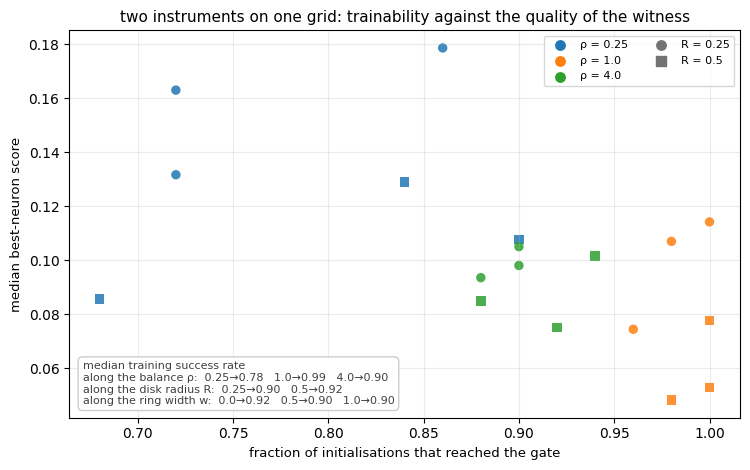

In [37]:
tr = dsw.trainability_table(cells)
merged = (EDGE[(EDGE.task == "relevant") & (EDGE.R < 1.0) & (EDGE["T"] == 1000)]
          .merge(tr[["cell", "success rate"]], on="cell"))
fig = dplt.plot_two_outcomes(merged,
    title="two instruments on one grid: trainability against the quality of the witness")
plt.show()

### What we see

**All 15 task-irrelevant cells trained completely at the first attempt — 50 of 50.** All failures without exception are
on the task-relevant side, and the worst cell — `w = 1.0, R = 0.5, ρ = 0.25` — collected 34 of 50.

**Along the balance the two instruments agree, and trainability speaks even more cleanly.** The median success rate is
0.99 at `ρ = 1`, 0.90 at `ρ = 4` and 0.78 at `ρ = 0.25`; the maximum falls on equality **in six lines of six** — where
the score gave four of six (§4.2). The asymmetry is the same: a starved ring is worse than a starved disk.

**Along the ring width both instruments agree too — nothing moves.** Medians 0.92 / 0.90 / 0.90, a range within a line
of 0.02–0.22 with no consistent sign, exactly as for the score on the stationary probe (§4.1).

**Along the disk radius, however, the instruments diverge, and this has to be named plainly.** The score improved with
the larger disk in nine pairs of nine (§4.3); trainability only in five of nine, worse in three and equal in one,
medians 0.90 against 0.92. Trainability is simply insensitive to this axis.

**The cloud in the plot is ordered, and it is ordered by the balance.** The cells with poor trainability are the same
ones that have a worse score, and they separate by colour, that is, by balance. If one of the instruments were
measuring noise, there would be no order.

### Conclusions

**Trainability is a second outcome of the experiment, not a nuisance.** Along two axes of three it responds to the same
variables and in the same direction as the score of the neurons, and along the balance even more definitely.

**The divergence along the disk axis is meaningful, not annoying.** Trainability measures how hard it is for the network
to reach perfect separation; the score measures how accurately a level set fits onto the inner edge. The disk radius
moves the second and does not move the first — that is, it changes not the difficulty of the task but the **place**
where the boundary runs. This is exactly the reading that §4.3 arrived at through the gap, and here it gets independent
support: were the disk effect an effect of difficulty, trainability would have had to follow it.

**A caveat about selection that has to be kept in mind when reading all the preceding sections.** The ensembles are
everywhere conditioned on passing the gate, and the pass rate differs across cells: "50 of 50" at one edge of the grid
against "50 of about 74" at the other. Topping up to the full `N` does not remove this conditioning. The direction of
the bias is conservative — the models selected are those that solved the task perfectly, that is, the bias works **in
favour of** a witness appearing where it is found anyway.

**The engineering consequence has already been put into the code.** The training loop now counts successes, not
attempts: up to 100 attempts, stopping at the required number of successes, with an exhausted ceiling printed loudly. A
cell that has not filled its ensemble within 100 attempts is a statement about the task, and a human has to look at it.